# ¿Qué se robaron, quién y cómo? Investigación forense del incidente PHP2Shell en TechCorp

**La situación.** El lunes 9 de noviembre de 2026, alguien de TI de TechCorp encontró en el servidor del portal interno un archivo que nadie reconocía: `thumb_8f3a.php`, metido en la carpeta donde se guardan las **fotos de perfil** de los empleados. Una carpeta de fotos no debería tener programas adentro. El servidor sigue funcionando, los datos siguen en la base y no hay nada más raro a simple vista: el intruso, si lo hubo, **borró lo que usó**.

**Nuestro papel.** Somos el equipo forense. No vimos el ataque y no podemos preguntarle nada al atacante. Lo único que tenemos son los **registros (logs)** que los sistemas de TechCorp fueron escribiendo durante la semana, como las cámaras de seguridad de un edificio. Con ellos debemos responder cinco preguntas:

| # | Pregunta | En palabras simples |
|---|---|---|
| 1 | **¿Cuándo?** | ¿A qué hora empezó, cuándo logró entrar, cuándo sacó los datos y cuándo se fue? |
| 2 | **¿Dónde?** | ¿Por qué puerta entró y qué dejó en el servidor? |
| 3 | **¿Cómo?** | ¿Qué falla aprovechó y qué pasos siguió? |
| 4 | **¿Quién?** | ¿Desde qué direcciones IP y con qué herramientas? |
| 5 | **¿Qué?** | ¿Qué datos de clientes y empleados vio y se llevó, **registro por registro**? |

**Las cuatro «cámaras» que tenemos** (cada una ve una parte distinta de lo que pasó):

| Fuente | Archivo | Es como… | Qué anota |
|---|---|---|---|
| Servidor web (Apache) | `web/access.jsonl` | el libro de visitas de la portería | Cada petición que llega al portal: desde qué IP, a qué página, a qué hora, cuántos bytes entraron y salieron |
| Aplicación (PHP) | `app/app.jsonl` | la bitácora del vigilante | Inicios de sesión, errores, accesos negados y **caídas** del servidor |
| Base de datos (auditoría) | `db/audit.jsonl` | el registro del archivo de documentos | Cada consulta a la base: con qué cuenta, qué tabla y **qué filas** devolvió |
| Integridad de archivos (FIM) | `fim/fim.jsonl` | la alarma de las puertas | Cada archivo que aparece o cambia en el servidor web |

**La herramienta central: las expresiones regulares.** Los registros son texto. Para convertirlos en evidencia que se pueda contar y cruzar usamos **expresiones regulares**: patrones que describen texto. Se presentan en la sección 0.1 y aparecen en cada paso clave, en recuadros «Expresión regular en uso».

**Cómo leer este notebook.** Primero explicamos la falla (Parte I). Después seguimos los pasos de una investigación forense (Parte II), según las guías **NIST SP 800-86** e **ISO/IEC 27037**: *preservar → procesar → analizar → concluir*. En cada paso decimos **qué buscamos y por qué**, mostramos el resultado y explicamos **qué significa**. El código de apoyo (estilos y gráficos) está plegado: se despliega con el triángulo de la izquierda.

> Laboratorio académico: los 500 empleados y 2000 clientes son ficticios y el ataque es una simulación controlada (no se usó ningún exploit real). Las IP «de Internet» son de rangos reservados para documentación.

---
# Parte I · La falla: ¿qué es PHP2Shell?

### Primero, tres conceptos

* **PHP** es el lenguaje con el que está hecho el portal (y cerca del 70 % de los sitios web: WordPress, Moodle, Drupal…). Cuando alguien abre una página, el servidor **ejecuta** el programa PHP y devuelve el resultado.
* **Subir un archivo** (por ejemplo, una foto de perfil) se hace con un formulario de tipo `multipart/form-data`: el navegador manda el archivo partido en trozos.
* **El progreso de subida** (`session.upload_progress`) es una función de PHP, activa por defecto, que va anotando *cuánto lleva subido* un archivo, para poder mostrar una barra de progreso. Se activa si el formulario incluye un campo llamado `PHP_SESSION_UPLOAD_PROGRESS`.

### La falla en palabras simples

PHP reserva memoria para anotar ese progreso. Cuando una petición se interrumpe a la fuerza en un mal momento (por ejemplo, al **quedarse sin memoria** con una subida enorme), PHP **devuelve** ese espacio de memoria pero **sigue guardando la dirección** donde estaba. Es como devolver la llave de un casillero y quedarse con una copia: la siguiente petición que atienda ese mismo proceso puede leer o escribir en un espacio que ya es de otro. Ese tipo de error se llama ***use-after-free*** («usar después de liberar»).

Bien manipulado, eso le permite al atacante:

1. **Leer memoria ajena** (CVE-2026-109618): restos de otras peticiones, como contraseñas, tokens o llaves, que se filtran en la cookie `PHPSESSID`.
2. **Ejecutar su propio código** en el servidor (CVE-2026-109619 junto con la anterior): es decir, tomar el control.

### ¿Por qué es tan grave?

| Característica | Por qué importa |
|---|---|
| **No necesita usuario ni contraseña** | PHP procesa el archivo subido **antes** de que el programa del portal revise si uno inició sesión. La puerta se abre antes de llegar al portero. |
| **Está en PHP, no en el portal** | No importa lo bien programado que esté el sitio: si corre un PHP vulnerable, está expuesto. Afecta a casi todas las versiones desde la 5.4 (2012). |
| **Gravedad 9,2 / 10** (CVSS v4) | Ejecución remota de código: lo peor que puede pasarle a un servidor. |

**Cronología real:** la descubrió Wiz Research y la reportó a PHP el 24 de agosto de 2026. Se publicó junto con el parche el **21 de octubre de 2026** (PHP **8.2.35, 8.3.36, 8.4.27 y 8.5.12**). Según Cloudflare, los intentos de ataque empezaron **en menos de una hora** y llegaron a millones al día siguiente. El portal de TechCorp corre **PHP 8.3.30**: no tenía el parche.

### ¿Por qué el ataque deja tanto «ruido»?

El exploit tiene que acertar con la forma exacta en que está organizada la memoria del servidor, y eso no se sabe de antemano. El atacante **prueba muchas veces**. Cada intento fallido **tumba el proceso** de Apache que lo atendió: el usuario ve un **error 500** y el servidor anota la caída. Esa ráfaga de subidas enormes seguidas de errores es justamente lo que vamos a buscar.

### ¿Cómo se representa el ataque en este laboratorio?

Por seguridad y por ética **no usamos el exploit real**. El portal tiene un *simulador* que reconoce el patrón del ataque (subida con `PHP_SESSION_UPLOAD_PROGRESS`, sin sesión iniciada) y produce **la misma huella** que dejaría el ataque de verdad:

| En un ataque real… | En el laboratorio… |
|---|---|
| Cada intento fallido corrompe la memoria y mata el proceso de Apache | El simulador responde **500** y anota la caída `AH00052 Segmentation fault`, hasta el intento 19 |
| Al acertar, el atacante escribe una **webshell** (una puerta trasera) en el servidor | Aparece `/uploads/avatars/thumb_8f3a.php`, que solo acepta una lista cerrada de órdenes |
| Las órdenes del atacante leen archivos y consultan la base de datos | Las consultas a la base son **reales** (sobre datos ficticios) y quedan en la auditoría |

Todo lo demás (Apache, PHP, MySQL, los logs, los archivos que se crean y se borran) es real.

### ¿Qué huellas debería dejar cada paso del ataque?

Antes de mirar los datos, un buen forense se pregunta: *si el ataque ocurrió, ¿dónde tendría que haber quedado registrado?* Esta tabla es nuestro mapa para la Parte II:

| Paso del atacante | Huella esperada | ¿En qué registro? |
|---|---|---|
| Explorar el sitio buscando páginas | Cientos de páginas inexistentes (error **404**) en pocos minutos | Servidor web |
| Lanzar el exploit | Subidas **enormes y sin sesión** a una página que acepta archivos, con **errores 500** | Servidor web |
| Los intentos fallidos | **Caídas** de procesos de Apache, una tras otra | Aplicación |
| El intento exitoso | Un **archivo `.php` nuevo** donde solo debería haber fotos | Integridad de archivos (FIM) |
| Dar órdenes por la webshell | Peticiones a ese archivo nuevo, con la orden escrita en la URL | Servidor web |
| Robar la base de datos | Consultas masivas, quizás con **otra cuenta** de base de datos | Auditoría de BD |
| Llevarse los datos | **Respuestas gigantes** hacia una IP externa | Servidor web |

### La idea central: ¿por qué se puede investigar aunque el atacante borre todo?

El atacante guardó los datos robados en archivos temporales (`/tmp/.d/…`), los descargó y **los borró**. En el servidor ya no queda nada de eso. Pero **cada orden que dio pasó por la portería**: tuvo que pedirla por HTTP, y el servidor web la anotó en su libro de visitas **antes** de obedecerla. Lo mismo pasó con cada consulta a la base de datos, que quedó en la auditoría.

Es el **principio de intercambio de Locard**: *todo contacto deja un rastro*. El atacante puede limpiar la escena (el servidor), pero no las cámaras que estaban en otro lugar y que no controlaba. Con esos rastros, cruzados entre sí, vamos a reconstruir el ataque **minuto a minuto y registro por registro**.

---
# Parte II · La investigación

## 0. Preparar el entorno de trabajo

**¿Qué significa «preparar el entorno»?** Es lo que hace un forense antes de tocar la evidencia: alistar la mesa y las herramientas, ponerse los guantes y separar lo que va a examinar de lo que va a producir. En nuestro caso, la celda siguiente (plegada, porque es técnica) hace cuatro cosas:

1. **Abre la caja de herramientas** (importa librerías de Python):

   | Herramienta | Para qué la usamos | Es como… |
   |---|---|---|
   | **DuckDB** | Hacer preguntas en lenguaje SQL a cientos de miles de líneas de log en segundos | un buscador muy rápido sobre tablas enormes |
   | **Pandas** | Manipular y mostrar tablas | Excel, pero desde código |
   | **Matplotlib / Seaborn** | Dibujar los gráficos | el graficador de Excel |
   | **scikit-learn** | Detectar comportamientos raros con aprendizaje automático | un detector de «esto no encaja» |

2. **Define dónde está cada cosa.** La evidencia vive en `/evidencia/logs`, una carpeta montada en **solo lectura**: aunque nos equivoquemos, el sistema no nos deja modificarla. Lo que nosotros producimos (gráficos, tablas, informes) va a otra carpeta, `salida/`. **Nunca se mezcla la evidencia con el trabajo del analista.**
3. **Abre una base de datos analítica vacía en memoria** (DuckDB), donde cargaremos los logs para consultarlos.
4. **Define el estilo de los gráficos** y unas funciones pequeñas para escribir números en formato colombiano (12.345,67).

Esta celda **todavía no analiza nada**; solo deja todo listo.

In [1]:
import base64, hashlib, ipaddress, json, os, re, time
from pathlib import Path
from urllib.parse import parse_qs

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from IPython.display import Markdown, display
import warnings
warnings.filterwarnings('ignore', category=DeprecationWarning)

BASE = Path.cwd().parent                                     # .../analisis
EVIDENCIA = Path(os.environ.get('EVIDENCIA') or BASE.parent / 'logs')
CONTEXTO = BASE / 'contexto'
SALIDA = BASE / 'salida'
FIG, LAKE = SALIDA / 'figuras', SALIDA / 'lake'
SOLUCIONARIO = next((p for p in [BASE / 'solucionario', BASE.parent / 'simulacion'] if p.exists()), None)
for p in (FIG, LAKE):
    p.mkdir(parents=True, exist_ok=True)

pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 220)
pd.set_option('display.max_columns', 30)
con = duckdb.connect()            # base de datos analítica en memoria

# --- Estilo de los gráficos (sobrio, apto para diapositivas) ---------------------------
TINTA, TINTA2, TENUE = '#0b0b0b', '#52514e', '#898781'
REJILLA, EJE, FONDO = '#e1e0d9', '#c3c2b7', '#fcfcfb'
AZUL, CRITICO, GRIS = '#2a78d6', '#d03b3b', '#b5b3aa'
RAMPA_AZUL = LinearSegmentedColormap.from_list('azul', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': FONDO, 'axes.facecolor': FONDO, 'savefig.facecolor': FONDO,
    'axes.edgecolor': EJE, 'axes.labelcolor': TINTA2, 'axes.titlecolor': TINTA, 'text.color': TINTA,
    'xtick.color': EJE, 'ytick.color': EJE, 'xtick.labelcolor': TINTA2, 'ytick.labelcolor': TINTA2,
    'axes.grid': True, 'grid.color': REJILLA, 'grid.linewidth': 0.6, 'grid.linestyle': '-',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'axes.titlesize': 13, 'axes.titleweight': 'semibold', 'axes.titlelocation': 'left', 'axes.titlepad': 12,
    'font.family': 'DejaVu Sans', 'font.size': 10.5, 'legend.frameon': False,
    'figure.dpi': 110, 'savefig.dpi': 200, 'savefig.bbox': 'tight', 'lines.linewidth': 2,
})

def guardar(fig, nombre):
    fig.savefig(FIG / f'{nombre}.png')
    plt.show()

def num(x, dec=0):
    '''Número en formato español: 12.345,67'''
    return f'{x:,.{dec}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

def mb(b):
    return num(b / 1_048_576, 2) + ' MB'

def formato_dias(ax):
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: (lambda d: f"{DIAS_ES[d.weekday()]} {d:%d/%m}")(mdates.num2date(v))))

DIAS_ES = ['lun', 'mar', 'mié', 'jue', 'vie', 'sáb', 'dom']

print('Evidencia:', EVIDENCIA, '| Salida:', SALIDA, '| DuckDB', duckdb.__version__)

Evidencia: /evidencia/logs | Salida: /home/analista/salida | DuckDB 1.1.3


**Resultado:** la celda confirma dónde está la evidencia y la versión del motor de análisis. Que el resultado quede impreso sirve para la **reproducibilidad**: cualquier otro perito puede repetir el análisis con las mismas herramientas y llegar a lo mismo.

## 0.1 La herramienta del caso: expresiones regulares

Los registros son **texto**. Antes de contar, cruzar o graficar, hay que sacar de ese texto los datos que importan: una dirección IP, un identificador escondido en un comentario, la orden que el atacante escribió en una URL. La herramienta para eso son las **expresiones regulares** (*regex*): un pequeño lenguaje para describir **patrones** de texto.

Una expresión regular no busca una palabra exacta: describe una **forma**. «Cuatro grupos de 1 a 3 dígitos separados por puntos» describe **cualquier** dirección IPv4, sin saber cuál.

**Las piezas que se usan en este caso:**

| Pieza | Significa | Ejemplo en esta investigación |
|---|---|---|
| `\d` | un dígito (0–9) | `\d+` encuentra `461` en `emp_461.png` |
| `\w` | una letra, un dígito o `_` | `FROM (\w+)` captura `clientes` |
| `\s` / `\S` | un espacio / cualquier cosa **menos** un espacio | `> (\S+)$` captura la ruta de un archivo |
| `.` | cualquier carácter | `^cat .*config` acepta lo que haya entre `cat` y `config` |
| `\.` `\*` `\?` | el carácter **literal** (la barra le quita el significado especial) | `\.php` es «punto php» |
| `+` `*` `?` | uno o más / cero o más / opcional | `[^']+` avanza hasta la siguiente comilla |
| `{n,m}` | entre n y m repeticiones | `\d{1,3}` son de 1 a 3 dígitos |
| `[abc]` / `[^abc]` | uno de esos caracteres / cualquiera **menos** esos | `[^']` es «todo menos la comilla» |
| `^` / `$` | inicio / fin del texto | `^rm ` exige que la orden **empiece** por `rm` |
| `a\|b` | una cosa o la otra | `(tar\|du)` |
| `( … )` | **grupo de captura**: la parte que queremos sacar | `request_id='([^']+)'` saca solo el identificador |
| `(?: … )` | agrupa **sin** capturar | `(?:\d{1,3}\.){3}` repite «número y punto» tres veces |
| `(?i)` | no distingue mayúsculas y minúsculas | `(?i)gobuster` también encuentra `GoBuster` |
| `\b` | borde de palabra | evita atrapar un pedazo de un número más largo |

La celda siguiente define `ver_regex()`, un visor que usaremos en todo el notebook: **resalta en amarillo** lo que atrapa un patrón dentro de un texto real y muestra en una tabla lo que capturó cada grupo. Después lo probamos con dos líneas sacadas tal cual de la evidencia.

In [2]:
from html import escape
from IPython.display import HTML

def ver_regex(patron, texto, titulo='', max_coincidencias=6):
    """Muestra qué atrapa una expresión regular dentro de un texto: coincidencias en amarillo y grupos en tabla."""
    rx = re.compile(patron)
    trozos, ultimo, grupos = [], 0, []
    for n, m in enumerate(rx.finditer(texto), start=1):
        if n > max_coincidencias:
            break
        trozos.append(escape(texto[ultimo:m.start()]))
        trozos.append('<mark style="background:#ffd966;color:#111;border-radius:3px;padding:1px 2px">'
                      f'{escape(m.group(0))}</mark>')
        ultimo = m.end()
        for g in range(1, rx.groups + 1):
            grupos.append({'coincidencia': n, 'grupo': g, 'capturó': m.group(g)})
    trozos.append(escape(texto[ultimo:]))
    total = len(rx.findall(texto))
    display(Markdown(f"**{titulo}**" if titulo else ''))
    display(HTML(
        '<div style="border:1px solid #c3c2b7;border-radius:6px;padding:8px 10px;margin:2px 0 6px">'
        f'<div style="font:12px monospace;color:#52514e;margin-bottom:6px">patrón: <code>{escape(patron)}</code> · '
        f'{total} coincidencia{"s" if total != 1 else ""}</div>'
        f'<div style="font:13px/1.5 monospace;white-space:pre-wrap;word-break:break-all">{"".join(trozos)}</div></div>'))
    if grupos:
        display(pd.DataFrame(grupos).style.hide(axis='index'))

# Dos líneas reales, tal como están en los archivos de evidencia
linea_web = next(open(EVIDENCIA / 'web' / 'access.jsonl', encoding='utf-8', errors='replace')).strip()
linea_bd = next(l for l in open(EVIDENCIA / 'db' / 'audit.jsonl', encoding='utf-8', errors='replace') if 'request_id=' in l).strip()

ver_regex(r'\b(?:\d{1,3}\.){3}\d{1,3}\b', linea_web, 'Ejemplo 1 · cualquier dirección IPv4 dentro de una línea del servidor web')
ver_regex(r'"ts":"(\d{4}-\d{2}-\d{2})T(\d{2}:\d{2}:\d{2})', linea_web, 'Ejemplo 2 · fecha y hora, cada una en su grupo')
ver_regex(r"request_id='([^']+)'", linea_bd, 'Ejemplo 3 · el identificador escondido en el comentario de una consulta SQL')

**Ejemplo 1 · cualquier dirección IPv4 dentro de una línea del servidor web**

**Ejemplo 2 · fecha y hora, cada una en su grupo**

coincidencia,grupo,capturó
1,1,2026-11-03
1,2,05:01:28


**Ejemplo 3 · el identificador escondido en el comentario de una consulta SQL**

coincidencia,grupo,capturó
1,1,avtmhLnv9gkWS2EMS2NEygAAAAI


**¿Qué vemos?** El mismo método sirve para cosas muy distintas: el ejemplo 1 encuentra **todas** las IP de la línea sin conocerlas de antemano; el 2 parte la fecha y la hora en dos grupos; el 3 saca un identificador de 27 caracteres escondido dentro de un comentario SQL. Ese tercer patrón será **la llave del caso** en la sección 7.

A lo largo del notebook, los recuadros **«Expresión regular en uso»** explican cada patrón pieza por pieza en el momento en que se usa.

## 1. Preservar la evidencia: la «huella digital» de cada archivo

**¿Qué buscamos?** Poder demostrar, por ejemplo ante un juez, que **los registros que analizamos son exactamente los que entregó TechCorp** y que nadie (ni siquiera nosotros) los cambió.

**¿Cómo?** Con un **hash SHA-256**. Es una función que lee un archivo completo y produce un código de 64 caracteres, como una **huella digital**:

* El mismo archivo siempre da la misma huella.
* Si se cambia **una sola letra** del archivo, la huella sale completamente distinta.
* Es prácticamente imposible fabricar dos archivos distintos con la misma huella.

Anotamos la huella de cada archivo **antes** de empezar, con la fecha y la hora. Eso es el inicio de la **cadena de custodia**: el registro de quién tuvo la evidencia, cuándo y en qué estado (en Colombia, la exige el Código de Procedimiento Penal, Ley 906 de 2004, para que una prueba sea válida). Al **final** del notebook volvemos a calcular las huellas: si coinciden, queda demostrado que el análisis no alteró nada.

In [3]:
def sha256(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, 'rb') as f:
        while chunk := f.read(bloque):
            h.update(chunk)
    return h.hexdigest()

filas = []
for ruta in sorted(EVIDENCIA.glob('*/*.jsonl')):
    with open(ruta, 'rb') as f:
        lineas = sum(1 for _ in f)
    filas.append({'fuente': ruta.parent.name, 'archivo': str(ruta.relative_to(EVIDENCIA)),
                  'tamaño_MB': round(ruta.stat().st_size / 1_048_576, 2), 'líneas': lineas, 'sha256': sha256(ruta)})
custodia = pd.DataFrame(filas)
custodia['adquirido_utc'] = pd.Timestamp.now(tz='UTC').strftime('%Y-%m-%dT%H:%M:%SZ')
custodia.to_csv(SALIDA / 'cadena_custodia.csv', index=False)
TOTAL_LINEAS = int(custodia['líneas'].sum())
display(custodia)
print(f'Total: {num(TOTAL_LINEAS)} líneas de log · {num(custodia["tamaño_MB"].sum(), 1)} MB')

,fuente,archivo,tamaño_MB,líneas,sha256,adquirido_utc
0,app,app/app.jsonl,3.18,10937,4f4285d5b6a7721e4797b45aa22a599d59b9f1d11bc4de327b009cb65614aa0b,2026-11-17T00:23:51Z
1,db,db/audit.jsonl,41.24,88508,0d20b830458a98bd7ae04198583faeb5f48a9376850ce4e3ce38afc90e19ecd1,2026-11-17T00:23:51Z
2,fim,fim/fim.jsonl,0.05,193,08f25c3f91bb61fbdf2bfdbe3c662d2219cc285566b2880b1e80d7c14e1a0e09,2026-11-17T00:23:51Z
3,web,web/access.jsonl,37.59,80042,a4de3c17fa7c201711eba5c1f11e472997afa3035a11e80b3b90f1d92d2c86bb,2026-11-17T00:23:51Z


Total: 179.680 líneas de log · 82,1 MB


**¿Qué encontramos?** Cuatro archivos, uno por fuente, con unas **180 000 líneas** en total (unos 80 MB de texto): demasiado para revisar a mano y justo el tipo de volumen donde hacen falta herramientas de *Big Data*. La columna `sha256` es la huella de cada uno, y la tabla se guarda en `salida/cadena_custodia.csv` como acta.

## 2. Cargar los registros para poder interrogarlos

**¿Qué buscamos?** Convertir 180 000 líneas de texto en **tablas** a las que se les puedan hacer preguntas, como *«¿qué IP pidió más páginas que no existen?»*.

**¿Cómo?** Cada línea de log es un evento en formato **JSON** (texto con pares `"campo": valor`). DuckDB los lee y los convierte en tablas, una por fuente. Tres cuidados de forense:

* **Le decimos a DuckDB el tipo de cada columna** (texto, número, fecha) en lugar de dejar que lo adivine. Así ningún dato se interpreta mal en silencio.
* **No perdemos líneas.** Apache a veces escribe caracteres raros (`\xHH`) que rompen el JSON. En vez de descartar esas líneas, las corregimos **al leerlas**, sin tocar el archivo original, y contamos cuántas fueron.
* **Unificamos la hora.** Los servidores anotan en hora universal (UTC). La pasamos a **hora de Colombia (UTC−5)** para que «las 2 de la madrugada» signifique lo mismo en todas las fuentes.

La celda de carga está plegada; abajo se ven sus resultados.

In [4]:
ESQUEMAS = {
    'web': {'ts': 'VARCHAR', 'server': 'VARCHAR', 'vhost': 'VARCHAR', 'request_id': 'VARCHAR', 'client_ip': 'VARCHAR',
            'method': 'VARCHAR', 'uri': 'VARCHAR', 'query': 'VARCHAR', 'protocol': 'VARCHAR', 'status': 'INTEGER',
            'bytes_sent': 'BIGINT', 'bytes_received': 'BIGINT', 'duration_us': 'BIGINT', 'content_type': 'VARCHAR',
            'user_agent': 'VARCHAR', 'referer': 'VARCHAR', 'user': 'VARCHAR'},
    'app': {'ts': 'VARCHAR', 'level': 'VARCHAR', 'component': 'VARCHAR', 'server': 'VARCHAR', 'request_id': 'VARCHAR',
            'client_ip': 'VARCHAR', 'user': 'VARCHAR', 'method': 'VARCHAR', 'uri': 'VARCHAR', 'event': 'VARCHAR',
            'message': 'VARCHAR', 'context': 'JSON'},
    'db':  {'ts': 'VARCHAR', 'server': 'VARCHAR', 'record_type': 'VARCHAR', 'connection_id': 'BIGINT', 'db_user': 'VARCHAR',
            'client_host': 'VARCHAR', 'database': 'VARCHAR', 'command_class': 'VARCHAR', 'tables': 'VARCHAR[]',
            'sqltext': 'VARCHAR', 'status': 'INTEGER', 'rows_sent': 'BIGINT', 'rows_affected': 'BIGINT',
            'duration_ms': 'DOUBLE', 'row_ids': 'BIGINT[]'},
    'fim': {'ts': 'VARCHAR', 'agent': 'VARCHAR', 'server': 'VARCHAR', 'event': 'VARCHAR', 'path': 'VARCHAR', 'size': 'BIGINT',
            'sha256': 'VARCHAR', 'owner': 'VARCHAR', 'mode': 'VARCHAR', 'process': 'VARCHAR'},
}

def leer(fuente):
    # Lector directo de DuckDB (rápido; se usa para la comparación con Parquet)
    cols = '{' + ', '.join(f"'{k}': '{v}'" for k, v in ESQUEMAS[fuente].items()) + '}'
    return f"read_json('{EVIDENCIA}/{fuente}/*.jsonl', format='newline_delimited', columns={cols}, ignore_errors=true)"

calidad = []
t0 = time.perf_counter()
for fuente in ESQUEMAS:
    estructura = json.dumps(ESQUEMAS[fuente])
    # Líneas crudas → normalización de \xHH → validación → JSON tipado
    con.execute(f'''
        CREATE OR REPLACE TEMP TABLE lineas AS
        SELECT linea, replace(linea, chr(92) || 'x', chr(92) || 'u00') AS normalizada
        FROM (SELECT unnest(string_split(content, chr(10))) AS linea FROM read_text('{EVIDENCIA}/{fuente}/*.jsonl'))
        WHERE linea <> ''
    ''')
    calidad.append(con.sql(f'''
        SELECT '{fuente}' AS fuente, COUNT(*) AS lineas,
               SUM((linea <> normalizada)::INT) AS normalizadas_xHH,
               SUM((NOT json_valid(normalizada))::INT) AS invalidas
        FROM lineas
    ''').df())
    con.execute(f'''
        CREATE OR REPLACE TABLE {fuente} AS
        WITH j AS (SELECT unnest(from_json(normalizada, '{estructura}')) FROM lineas WHERE json_valid(normalizada))
        SELECT CAST(replace(ts, 'Z', '') AS TIMESTAMP) - INTERVAL 5 HOUR AS ts,      -- hora Colombia
               CAST(replace(ts, 'Z', '') AS TIMESTAMP)                     AS ts_utc,
               * EXCLUDE (ts)
        FROM j
    ''')
con.execute('DROP TABLE lineas')
display(pd.concat(calidad, ignore_index=True))
# Normalización: en el log de Apache "-" significa "vacío"
con.execute('''
    CREATE OR REPLACE TABLE web AS
    SELECT * EXCLUDE (content_type, referer, "user"),
           NULLIF(content_type, '-') AS content_type, NULLIF(referer, '-') AS referer, NULLIF("user", '-') AS usuario
    FROM web
''')
t_carga = time.perf_counter() - t0

resumen = con.sql('''
    SELECT 'web' AS fuente, COUNT(*) AS eventos, MIN(ts) AS desde, MAX(ts) AS hasta FROM web UNION ALL
    SELECT 'app', COUNT(*), MIN(ts), MAX(ts) FROM app UNION ALL
    SELECT 'db',  COUNT(*), MIN(ts), MAX(ts) FROM db  UNION ALL
    SELECT 'fim', COUNT(*), MIN(ts), MAX(ts) FROM fim
''').df()
display(resumen)
cargados = int(resumen['eventos'].sum())
print(f'{num(cargados)} eventos cargados en {num(t_carga, 1)} s  ·  líneas no interpretables: {TOTAL_LINEAS - cargados}')

,fuente,lineas,normalizadas_xHH,invalidas
0,web,80042,0.0,0.0
1,app,10937,0.0,0.0
2,db,88508,0.0,0.0
3,fim,193,0.0,0.0


,fuente,eventos,desde,hasta
0,web,80042,2026-11-03 00:00:01.289,2026-11-16 17:40:33.381
1,app,10937,2026-11-03 00:00:30.826,2026-11-10 01:04:16.847
2,db,88508,2026-11-03 00:00:01.405,2026-11-10 01:42:40.083
3,fim,193,2026-11-03 07:31:11.965,2026-11-09 23:59:47.081


179.680 eventos cargados en 13,9 s  ·  líneas no interpretables: 0


**¿Qué encontramos?** La primera tabla es un **control de calidad**: cuántas líneas tenía cada archivo y cuántas no se pudieron interpretar (deben ser 0: no se perdió evidencia). La segunda muestra qué periodo cubre cada fuente: del **martes 3 al lunes 9 de noviembre**, la semana que entregó TechCorp.

### 2.1 Delimitar el caso y crear el *data lake*

Dos tareas más antes de analizar:

* **La ventana del caso.** Solo nos interesa la semana entregada. Si alguien navegó el portal después (por ejemplo, durante esta presentación), esos eventos se dejan fuera para no contaminar los gráficos.
* **El *data lake*.** Guardamos una copia de los registros en formato **Parquet**, separada por día. En JSON cada línea repite los nombres de los campos y todo es texto. Parquet guarda los datos **por columnas** y comprimidos, como un archivador ordenado por cajones en vez de una pila de hojas sueltas. Es el formato que usan las plataformas de Big Data (Spark, Databricks, BigQuery).

In [5]:
# Ventana del caso: el tramo más largo de días consecutivos con actividad (lo que entregó TechCorp).
# Eventos fuera de ella (p. ej., alguien navegando el portal durante la demostración) no se mezclan en los gráficos.
dias = con.sql('SELECT CAST(ts AS DATE) AS d, COUNT(*) AS n FROM web GROUP BY 1 ORDER BY 1').df()
tramo = dias.groupby((dias['d'].diff() != pd.Timedelta(days=1)).cumsum())['d'].agg(['min', 'max', 'count']).sort_values('count').iloc[-1]
CASO_INI, CASO_FIN = pd.Timestamp(tramo['min']), pd.Timestamp(tramo['max']) + pd.Timedelta(days=1)
fuera = int(dias.loc[(dias['d'] < CASO_INI) | (dias['d'] >= CASO_FIN), 'n'].sum())
print(f'Ventana del caso: {CASO_INI:%d/%m/%Y} → {CASO_FIN:%d/%m/%Y} · peticiones fuera de la ventana: {fuera}')

# Data lake: Parquet particionado por día (formato columnar comprimido)
for fuente in ESQUEMAS:
    con.execute(f"COPY (SELECT *, CAST(ts AS DATE) AS dia FROM {fuente}) TO '{LAKE / fuente}' "
                "(FORMAT PARQUET, PARTITION_BY (dia), OVERWRITE_OR_IGNORE, COMPRESSION ZSTD)")

tam_json = sum(p.stat().st_size for p in EVIDENCIA.glob('*/*.jsonl'))
tam_parquet = sum(p.stat().st_size for p in LAKE.rglob('*.parquet'))

consulta = "SELECT status, COUNT(*) AS n, SUM(bytes_sent) AS bytes FROM {} GROUP BY status"
t0 = time.perf_counter(); con.sql(consulta.format(leer('web'))).fetchall(); t_json = time.perf_counter() - t0
t0 = time.perf_counter(); con.sql(consulta.format(f"read_parquet('{LAKE}/web/**/*.parquet')")).fetchall(); t_pq = time.perf_counter() - t0

display(pd.DataFrame({
    'formato': ['JSON (crudo)', 'Parquet + ZSTD'],
    'tamaño': [mb(tam_json), mb(tam_parquet)],
    'consulta de agregación (s)': [round(t_json, 3), round(t_pq, 3)],
}))
print(f'Parquet ocupa el {tam_parquet / tam_json:.0%} del JSON y responde {t_json / max(t_pq, 1e-6):.0f}× más rápido.')

Ventana del caso: 03/11/2026 → 11/11/2026 · peticiones fuera de la ventana: 3


,formato,tamaño,consulta de agregación (s)
0,JSON (crudo),"82,07 MB",0.122
1,Parquet + ZSTD,"5,09 MB",0.015


Parquet ocupa el 6% del JSON y responde 8× más rápido.


**¿Qué encontramos?** La misma información ocupa **una fracción** del espacio en Parquet y las consultas responden **varias veces más rápido**. Con una semana de un portal pequeño la diferencia es de segundos; con meses de registros de una empresa grande, es la diferencia entre que la investigación sea viable o no.

## 3. ¿Cómo se ve una semana normal? (la línea base)

**¿Qué buscamos?** Para reconocer algo raro primero hay que saber qué es lo normal. Un médico no puede decir que alguien tiene fiebre si no sabe que lo normal son 37 °C. Esa «temperatura normal» del portal es la **línea base**: cuánta gente lo usa, a qué horas, qué páginas visita y con qué resultados.

Las tablas siguientes muestran el resumen general, los **códigos de respuesta** y las páginas más visitadas. Los códigos que más nos importan:

| Código | Significa | ¿Normal? |
|---|---|---|
| **200** | «Aquí tiene la página» | Lo esperado |
| **302** | «Vaya a otra página» (por ejemplo, al login si no ha iniciado sesión) | Normal |
| **403** | «No tiene permiso» | Pocos: empleados curioseando |
| **404** | «Esa página no existe» | Pocos: enlaces viejos. **Muchos seguidos = alguien explorando** |
| **500** | «El servidor falló» | Casi ninguno. **Una ráfaga = algo está rompiendo el servidor** |

In [6]:
display(con.sql('''
    SELECT COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips, COUNT(DISTINCT usuario) AS usuarios,
           COUNT(DISTINCT uri) AS uris, ROUND(SUM(bytes_sent) / 1048576, 1) AS mb_enviados,
           ROUND(AVG(duration_us) / 1000, 1) AS ms_promedio
    FROM web
''').df())

display(con.sql('''
    SELECT status AS codigo, COUNT(*) AS peticiones, ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 2) AS porcentaje
    FROM web GROUP BY 1 ORDER BY 1
''').df())

display(con.sql(r'''
    SELECT regexp_replace(uri, '\d+', 'N') AS endpoint, COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips
    FROM web GROUP BY 1 ORDER BY 2 DESC LIMIT 12
''').df())

,peticiones,ips,usuarios,uris,mb_enviados,ms_promedio
0,80042,693,499,675,91.8,33.8


,codigo,peticiones,porcentaje
0,200,72089,90.06
1,301,15,0.02
2,302,6757,8.44
3,403,72,0.09
4,404,1086,1.36
5,500,23,0.03


,endpoint,peticiones,ips
0,/api/health.php,10080,1
1,/login.php,8704,620
2,/clientes/ver.php,8578,584
3,/api/buscar.php,6454,426
4,/dashboard.php,5613,589
5,/clientes/index.php,5551,575
6,/tickets/ver.php,4886,540
7,/assets/css/portal.css,3399,588
8,/assets/js/portal.js,3399,588
9,/assets/img/logo.svg,3399,588


**¿Qué encontramos?** Unas **80 000 visitas** de casi 700 IP y 500 empleados en la semana. Cerca del **90 % son respuestas 200**: el portal funciona bien. Los **500 son apenas una veintena** en toda la semana, así que cualquier grupo de ellos merece atención. Las páginas más visitadas son las que se esperan en una oficina: el chequeo del monitoreo, el login, la ficha de clientes, el buscador y el inicio.

> **Expresión regular en uso: `\d+` → `N`.** En la tercera tabla de arriba, `regexp_replace(uri, '\d+', 'N')` cambia **cada grupo de dígitos** por la letra `N`. Así, `emp_17.png` y `emp_461.png` cuentan como la misma página, `emp_N.png`. Sin ese reemplazo, cada empleado sería una «página» distinta y la línea base se perdería entre miles de filas sueltas. `\d` es un dígito y `+` significa «uno o más seguidos».

In [7]:
display(con.sql(r'''
    SELECT uri AS original, regexp_replace(uri, '\d+', 'N') AS agrupada
    FROM web WHERE regexp_matches(uri, '\d') GROUP BY 1 ORDER BY random() LIMIT 5
''').df())

,original,agrupada
0,/uploads/avatars/emp_170.png,/uploads/avatars/emp_N.png
1,/uploads/avatars/emp_291.png,/uploads/avatars/emp_N.png
2,/uploads/avatars/emp_242.png,/uploads/avatars/emp_N.png
3,/uploads/avatars/emp_271.png,/uploads/avatars/emp_N.png
4,/uploads/avatars/emp_349.png,/uploads/avatars/emp_N.png


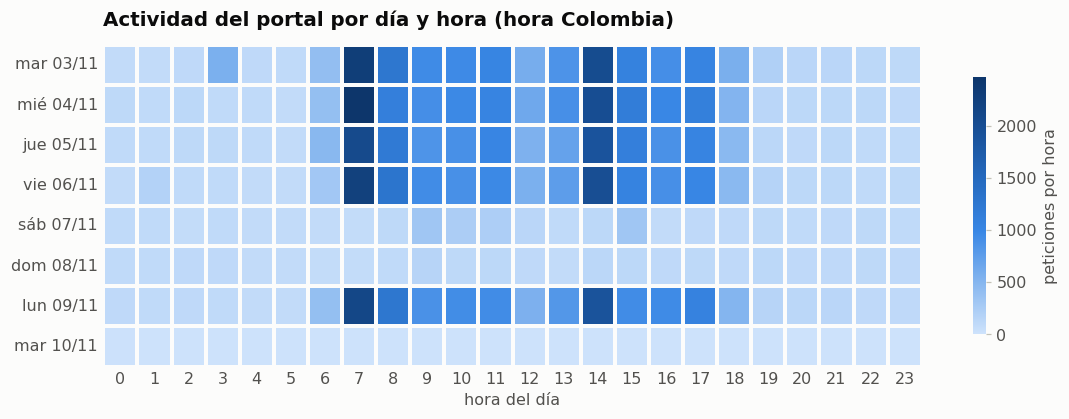

In [8]:
mapa = con.sql('''
    SELECT CAST(ts AS DATE) AS dia, hour(ts) AS hora, COUNT(*) AS n
    FROM web WHERE ts >= ? AND ts < ? GROUP BY ALL ORDER BY 1
''', params=[CASO_INI.to_pydatetime(), CASO_FIN.to_pydatetime()]).df()
mapa['etiqueta'] = mapa['dia'].map(lambda d: f"{DIAS_ES[d.weekday()]} {d:%d/%m}")
tabla = mapa.pivot_table(index='etiqueta', columns='hora', values='n', fill_value=0, sort=False)
tabla = tabla.reindex(columns=range(24), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
sns.heatmap(tabla, cmap=RAMPA_AZUL, linewidths=1.5, linecolor=FONDO, ax=ax,
            cbar_kws={'label': 'peticiones por hora', 'shrink': 0.8})
ax.set_title('Actividad del portal por día y hora (hora Colombia)')
ax.set_xlabel('hora del día'); ax.set_ylabel('')
ax.tick_params(length=0)
guardar(fig, 'fig01_mapa_calor_actividad')

**¿Qué encontramos?** Cada fila del mapa es un día y cada columna una hora; cuanto más oscuro, más visitas. El patrón es el de **una oficina**: actividad de 8:00 a 12:00 y de 14:00 a 18:00 entre semana, casi nada el fin de semana y un piso constante de noche (el monitoreo automático y el turno nocturno de soporte).

**Primera pista:** la madrugada del **viernes 06/11** tiene una mancha que no encaja con ese patrón. Todavía no sabemos qué es; solo sabemos dónde mirar.

## 4. Buscar lo que no encaja (detección de anomalías)

### 4.1 La «ficha de comportamiento» de cada IP

**¿Qué buscamos?** Separar a los empleados normales de las herramientas automáticas y de un posible atacante. Para eso armamos, para cada IP, una ficha con rasgos que delatan comportamientos distintos:

| Rasgo | Qué delata si es muy alto |
|---|---|
| Cantidad de peticiones y de páginas distintas | Un programa recorriendo el sitio, no una persona |
| Proporción de **404** | Alguien probando páginas que no existen (exploración) |
| Proporción de **500** | Alguien rompiendo el servidor |
| Respuesta **más grande** que recibió | Una descarga masiva (posible robo de datos) |
| Petición **más grande** que envió | Una carga útil (posible exploit) |
| Proporción de envíos (POST) | Alguien que manda mucho y lee poco |
| Actividad **nocturna** | Uso fuera de horario de oficina |
| Proporción de peticiones **con sesión iniciada** | Un empleado (alta) frente a un desconocido (baja) |

Además clasificamos cada IP según el **inventario de red** de TechCorp: oficina (LAN), VPN, monitoreo o Internet.

In [9]:
perfil = con.sql('''
    SELECT client_ip AS ip,
           COUNT(*)                                        AS peticiones,
           COUNT(DISTINCT uri)                             AS uris_distintas,
           AVG((status = 404)::INT)                        AS tasa_404,
           AVG((status >= 500)::INT)                       AS tasa_5xx,
           SUM(bytes_sent)                                 AS bytes_enviados,
           MAX(bytes_sent)                                 AS max_bytes_respuesta,
           ARG_MAX(ts, bytes_sent)                         AS ts_max_bytes,
           MAX(bytes_received)                             AS max_bytes_peticion,
           AVG((method = 'POST')::INT)                     AS tasa_post,
           AVG((hour(ts) < 6 OR hour(ts) >= 22)::INT)      AS tasa_nocturna,
           AVG((usuario IS NOT NULL)::INT)                 AS tasa_autenticada,
           COUNT(DISTINCT user_agent)                      AS agentes,
           ARG_MAX(user_agent, ts)                         AS ultimo_agente,
           MIN(ts) AS primera, MAX(ts) AS ultima
    FROM web GROUP BY client_ip
''').df()

# Zona de cada IP según el INVENTARIO DE RED de TechCorp (no según si la IP "parece" privada:
# por ejemplo, Python considera privadas las IP de documentación 203.0.113.0/24).
inventario = pd.read_csv(CONTEXTO / 'inventario_red.csv')
redes = sorted(((ipaddress.ip_network(r.red), r.zona) for r in inventario.itertuples()), key=lambda x: -x[0].prefixlen)

def zona(ip):
    a = ipaddress.ip_address(ip)
    if a.is_loopback:
        return 'Local'
    return next((z.replace('LAN oficinas', 'LAN') for red, z in redes if a in red), 'Internet')

perfil['zona'] = perfil['ip'].map(zona)
print(f'{len(perfil):,} IP distintas:', perfil['zona'].value_counts().to_dict())

693 IP distintas: {'LAN': 394, 'VPN': 195, 'Internet': 102, 'Monitoreo': 2}


### 4.2 Medir qué tan rara es cada IP

Con casi 700 fichas no se puede mirar una por una. Usamos dos métodos que se complementan:

* **Puntuación z robusta.** Mide **cuántos «pasos» se aleja** una IP de lo típico en cada rasgo. Por ejemplo, si lo normal es que el 1 % de las visitas den 404 y una IP tiene el 80 %, está muy lejos. Usamos la **mediana** en vez del promedio porque el promedio se deja arrastrar por los mismos casos extremos que buscamos. Ventaja: dice **en qué** rasgo es rara la IP, y eso se puede explicar.
* **Isolation Forest** (aprendizaje automático no supervisado). Funciona como el juego de las «20 preguntas»: hace cortes al azar en los datos hasta dejar cada IP sola. A una IP normal, rodeada de muchas parecidas, cuesta muchos cortes aislarla. Una IP rara queda sola **con muy pocos cortes**. Ventaja: detecta combinaciones raras de varios rasgos a la vez, sin que le enseñemos qué es un ataque.

In [10]:
from sklearn.ensemble import IsolationForest

FEATURES = {  # transformación logarítmica para magnitudes con colas largas
    'peticiones': np.log1p, 'uris_distintas': np.log1p, 'tasa_404': None, 'tasa_5xx': None,
    'max_bytes_respuesta': np.log1p, 'max_bytes_peticion': np.log1p, 'tasa_post': None, 'tasa_nocturna': None,
}
X = pd.DataFrame({c: (f(perfil[c]) if f else perfil[c]) for c, f in FEATURES.items()})

def z_robusto(s):
    mediana = s.median()
    escala = 1.4826 * (s - mediana).abs().median()
    if escala == 0:
        escala = s.std() or 1.0
    return (s - mediana) / escala

Z = X.apply(z_robusto)
perfil['z_max'] = Z.abs().max(axis=1).round(1)
perfil['motivo'] = Z.abs().idxmax(axis=1)

iso = IsolationForest(n_estimators=400, contamination='auto', random_state=2026).fit(X)
perfil['puntaje_if'] = (-iso.score_samples(X)).round(3)

cols = ['ip', 'zona', 'peticiones', 'tasa_404', 'tasa_5xx', 'max_bytes_respuesta', 'max_bytes_peticion',
        'tasa_nocturna', 'tasa_autenticada', 'ultimo_agente', 'puntaje_if', 'z_max', 'motivo']
top = perfil.sort_values('puntaje_if', ascending=False).head(15)[cols]
display(top.style.format({'tasa_404': '{:.0%}', 'tasa_5xx': '{:.0%}', 'tasa_nocturna': '{:.0%}', 'tasa_autenticada': '{:.0%}',
                          'max_bytes_respuesta': '{:,}', 'max_bytes_peticion': '{:,}'}).hide(axis='index'))

ip,zona,peticiones,tasa_404,tasa_5xx,max_bytes_respuesta,max_bytes_peticion,tasa_nocturna,tasa_autenticada,ultimo_agente,puntaje_if,z_max,motivo
203.0.113.66,Internet,112,59%,16%,"1,432","685,699",100%,0%,python-requests/2.32.3,0.778000,26.100000,tasa_5xx
203.0.113.67,Internet,2,0%,0%,"7,885,732",259,100%,0%,curl/8.5.0,0.700000,27.300000,max_bytes_respuesta
10.10.5.20,LAN,463,92%,0%,985,351,100%,0%,TechCorp-SOC-Scanner/3.2 (+https://soc.techcorp.local; CAB-2026-114),0.698000,19.300000,uris_distintas
10.10.0.5,Monitoreo,10080,0%,0%,273,217,33%,0%,Zabbix,0.694000,11.900000,uris_distintas
10.10.0.6,Monitoreo,2016,0%,0%,253,254,33%,0%,check_http/v2.3.3 (nagios-plugins 2.3.3),0.677000,11.900000,uris_distintas
192.0.2.233,Internet,1,100%,0%,949,318,100%,0%,"Mozilla/5.0 (Windows NT 6.1; WOW64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/49.0.2623.112 Safari/537.36",0.630000,11.900000,uris_distintas
198.51.100.205,Internet,1,100%,0%,949,221,100%,0%,curl/7.88.1,0.630000,11.900000,uris_distintas
198.51.100.77,Internet,202,90%,0%,"1,010",392,0%,0%,Mozilla/5.0 zgrab/0.x,0.629000,14.200000,uris_distintas
172.24.0.1,Internet,3,0%,0%,"1,420",88,0%,0%,curl/8.18.0,0.619000,9.600000,uris_distintas
192.0.2.226,Internet,1,100%,0%,949,235,100%,0%,Go-http-client/1.1,0.615000,11.900000,uris_distintas


**¿Qué encontramos?** Las 15 IP más raras según el modelo. Hay de todo: las dos IP `203.0.113.x`, pero también los servidores de **monitoreo** (miles de visitas exactas cada minuto), **escáneres** y empleados que hicieron **exportaciones grandes**.

**Lección importante:** el algoritmo encuentra lo **raro**, no lo **malicioso**. Que algo sea inusual no significa que sea un ataque. Por eso, después de la estadística siempre viene el análisis humano con contexto (sección 4.5).

### 4.3 Ráfagas de páginas inexistentes: alguien explorando

**¿Qué buscamos?** Antes de atacar, un intruso hace **reconocimiento**: usa herramientas como *gobuster* que prueban cientos de nombres de página (`/admin`, `/backup`, `/config.php`…) para ver cuáles existen. Casi todos dan **404**. Una persona comete un error de vez en cuando; una herramienta genera **decenas por minuto**. Buscamos IP con **20 o más 404 en un mismo minuto**.

In [11]:
rafagas = con.sql('''
    WITH m AS (
        SELECT client_ip, date_trunc('minute', ts) AS minuto, COUNT(*) AS n404, ANY_VALUE(user_agent) AS agente
        FROM web WHERE status = 404 GROUP BY ALL
    )
    SELECT client_ip AS ip, MIN(minuto) AS desde, MAX(minuto) + INTERVAL 1 MINUTE AS hasta,
           SUM(n404) AS total_404, MAX(n404) AS max_404_por_minuto, ANY_VALUE(agente) AS user_agent
    FROM m WHERE n404 >= 20 GROUP BY client_ip ORDER BY desde
''').df()
display(rafagas)

,ip,desde,hasta,total_404,max_404_por_minuto,user_agent
0,10.10.5.20,2026-11-03 03:00:00,2026-11-03 03:07:00,426.0,67,TechCorp-SOC-Scanner/3.2 (+https://soc.techcorp.local; CAB-2026-114)
1,203.0.113.66,2026-11-06 01:52:00,2026-11-06 01:53:00,53.0,53,gobuster/3.6
2,198.51.100.77,2026-11-07 15:21:00,2026-11-07 15:24:00,181.0,63,Mozilla/5.0 zgrab/0.x


**¿Qué encontramos?** **Tres exploraciones**, todas muy parecidas en los números:

* `10.10.5.20` (martes 03/11, 3:00 a. m.): se identifica como el escáner del equipo de seguridad de TechCorp.
* `203.0.113.66` (madrugada del viernes 06/11): usa **gobuster**, una herramienta de atacantes.
* `198.51.100.77` (sábado 07/11): usa **zgrab**, un escáner de Internet.

Un escaneo, por sí solo, **no prueba** que hubo una intrusión: en Internet todos los servidores son escaneados a diario. La pregunta que decide es **qué pasó después** con cada una de estas IP.

### 4.4 El tamaño de las respuestas: ¿salió algo grande?

**¿Qué buscamos?** Robar datos (*exfiltrar*) deja una huella física: **muchos bytes saliendo** del servidor hacia alguien. Una página del portal pesa unos pocos KB; una descarga de miles de registros pesa megas. Buscamos las respuestas más grandes de la semana y las comparamos con lo normal (el **percentil 99**: el tamaño que el 99 % de las respuestas no supera).

In [12]:
p99 = con.sql("SELECT quantile_cont(bytes_sent, 0.99) FROM web WHERE status = 200").fetchone()[0]
grandes = con.sql(f'''
    SELECT ts, client_ip, usuario, method, uri, query, status, bytes_sent, user_agent
    FROM web WHERE bytes_sent > 100000 AND uri NOT LIKE '/uploads/avatars/emp_%'
    ORDER BY bytes_sent DESC LIMIT 12
''').df()
print(f'Percentil 99 de una respuesta normal: {num(p99 / 1024, 1)} KB (las páginas viajan comprimidas con gzip)')
display(grandes.style.format({'bytes_sent': '{:,}'}).hide(axis='index'))

Percentil 99 de una respuesta normal: 2,3 KB (las páginas viajan comprimidas con gzip)


ts,client_ip,usuario,method,uri,query,status,bytes_sent,user_agent
2026-11-06 02:00:16.500000,203.0.113.67,None,GET,/uploads/avatars/thumb_8f3a.php,?dl=L3RtcC8udy50Z3o=,200,"7,885,732",curl/8.5.0
2026-11-04 10:13:10.008000,10.10.3.112,lmora,GET,/reportes/exportar.php,?tipo=clientes,200,"257,393",Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-09 16:42:18.144000,10.10.6.139,lcaicedo,GET,/reportes/exportar.php,?tipo=clientes,200,"257,393",Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-06 01:59:35.500000,203.0.113.67,None,GET,/uploads/avatars/thumb_8f3a.php,?dl=L3RtcC8uZC50Z3o=,200,"163,525",curl/8.5.0
2026-11-09 16:43:08.144000,10.10.6.139,lcaicedo,GET,/reportes/exportar.php,?tipo=tickets,200,"110,997",Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-09 16:05:50.643000,10.10.3.228,lflorez2,GET,/reportes/exportar.php,?tipo=tickets,200,"110,188",Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0
2026-11-09 15:14:18.898000,10.10.3.131,epardo,GET,/reportes/exportar.php,?tipo=tickets,200,"109,804","Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/129.0.0.0 Safari/537.36"
2026-11-09 17:41:19.491000,10.8.0.171,egomez,GET,/reportes/exportar.php,?tipo=tickets,200,"108,076","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36"
2026-11-09 18:27:40.248000,10.10.3.166,adiaz,GET,/reportes/exportar.php,?tipo=tickets,200,"105,240","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36"
2026-11-09 16:34:14.250000,10.10.3.229,lrodriguez,GET,/reportes/exportar.php,?tipo=tickets,200,"103,806","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/18.1 Safari/605.1.15"


**¿Qué encontramos?** El 99 % de las respuestas normales pesa **menos de 3 KB**. Las respuestas más grandes de la semana son de dos tipos: las **exportaciones de Excel** (CSV) de empleados de Finanzas y Gerencia, de unos cientos de KB, y unas descargas de una IP externa, **mucho más grandes**, hechas a un archivo que no es parte del portal. El gráfico siguiente lo muestra en el tiempo.

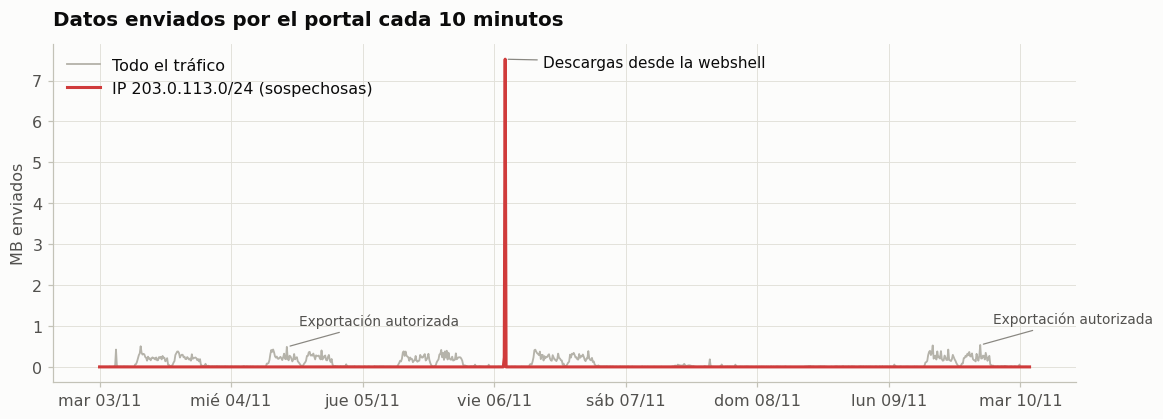

In [13]:
serie = con.sql('''
    SELECT time_bucket(INTERVAL 10 MINUTE, ts) AS t,
           SUM(bytes_sent) / 1048576.0 AS mb_total,
           SUM(CASE WHEN client_ip LIKE '203.0.113.%' THEN bytes_sent ELSE 0 END) / 1048576.0 AS mb_sospechoso
    FROM web WHERE ts >= ? AND ts < ? GROUP BY 1 ORDER BY 1
''', params=[CASO_INI.to_pydatetime(), CASO_FIN.to_pydatetime()]).df()

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(serie['t'], serie['mb_total'], color=GRIS, lw=1.2, label='Todo el tráfico')
ax.plot(serie['t'], serie['mb_sospechoso'], color=CRITICO, lw=2, label='IP 203.0.113.0/24 (sospechosas)')
pico_ext = serie.loc[serie['mb_sospechoso'].idxmax()]
ax.annotate('Descargas desde la webshell', xy=(pico_ext['t'], pico_ext['mb_sospechoso']),
            xytext=(25, -5), textcoords='offset points', color=TINTA, fontsize=10,
            arrowprops=dict(arrowstyle='-', color=TENUE, lw=0.8))
exportes = con.sql("SELECT MIN(ts) AS t FROM web WHERE uri = '/reportes/exportar.php' AND query LIKE '%clientes%' AND status = 200 GROUP BY CAST(ts AS DATE)").df()
for t in exportes['t']:
    y = serie.loc[(serie['t'] - t).abs().idxmin(), 'mb_total']
    ax.annotate('Exportación autorizada', xy=(t, y), xytext=(8, 14), textcoords='offset points', color=TINTA2, fontsize=9,
                arrowprops=dict(arrowstyle='-', color=TENUE, lw=0.8))
ax.set_title('Datos enviados por el portal cada 10 minutos')
ax.set_ylabel('MB enviados')
ax.xaxis.set_major_locator(mdates.DayLocator())
formato_dias(ax)
ax.legend(loc='upper left')
guardar(fig, 'fig02_bytes_enviados')

**¿Qué encontramos?** La línea gris es todo lo que el portal envió, cada 10 minutos, durante la semana: se ve el ritmo de oficina de cada día. Las **exportaciones autorizadas** apenas se notan. El viernes 06/11 de madrugada hay un **pico rojo de varios MB** hacia IP `203.0.113.x`, a una hora en que no hay casi nadie trabajando. Es la señal más clara hasta ahora.

### 4.5 Descartar las falsas alarmas: el contexto manda

**¿Qué buscamos?** Una anomalía no es un incidente. Antes de acusar a una IP hay que preguntarle a la empresa si eso era esperado. Usamos dos documentos que entregó TechCorp:

* El **registro de cambios aprobados (CAB)**: actividades inusuales pero autorizadas por escrito, con fecha, hora e IP (por ejemplo, «el martes a las 3 a. m. seguridad escanea el portal»).
* El **inventario de red**: qué rangos de IP son de la oficina, de la VPN y de los sistemas de monitoreo.

A cada IP sospechosa le aplicamos estas reglas: si estaba autorizada, si es un sistema de monitoreo o si es un empleado con sesión iniciada, queda **explicada**. Si es un escaneo externo, revisamos si **logró algo más** que ver el formulario de login. Las que no tengan explicación pasan a investigación.

In [14]:
cambios = pd.read_csv(CONTEXTO / 'registro_cambios.csv', parse_dates=['fecha_inicio_local', 'fecha_fin_local'])
display(cambios)

def explicar(fila):
    ip = ipaddress.ip_address(fila.ip)
    for c in cambios.itertuples():
        red = ipaddress.ip_network(c.ip_origen, strict=False)
        ini, fin = c.fecha_inicio_local.tz_localize(None), c.fecha_fin_local.tz_localize(None)
        # La anomalía (su respuesta más grande / su actividad) debe caer dentro de la ventana aprobada
        if ip in red and ini <= fila.ts_max_bytes <= fin:
            return f'Autorizado ({c.id_cambio})'
    if fila.zona == 'Monitoreo':
        return 'Monitoreo (inventario de red)'
    if fila.zona == 'Local':
        return 'Conexión interna del propio servidor'
    if fila.zona in ('LAN', 'VPN') and fila.tasa_autenticada > 0.5:
        return 'Empleado autenticado'
    return None

# IP llamativas: top del Isolation Forest + las de ráfagas 404 + las de respuestas grandes
llamativas = set(top['ip']) | set(rafagas['ip']) | set(grandes['client_ip'])
triage = perfil[perfil['ip'].isin(llamativas)].copy()
triage['explicacion'] = triage.apply(explicar, axis=1)

# ¿La IP obtuvo algo más que el formulario de login? (éxito tras el escaneo)
exito = con.sql('''
    SELECT client_ip AS ip, COUNT(*) AS respuestas_200_no_publicas, ANY_VALUE(uri) AS ejemplo
    FROM web
    WHERE status = 200 AND usuario IS NULL
      AND uri NOT IN ('/login.php', '/robots.txt', '/favicon.ico', '/api/health.php', '/legacy/status.php')
      AND uri NOT LIKE '/assets/%'
    GROUP BY 1
''').df()
triage = triage.merge(exito, on='ip', how='left').fillna({'respuestas_200_no_publicas': 0})
triage['veredicto'] = np.where(triage['explicacion'].notna(), 'Explicada (falsa alarma)',
                       np.where(triage['respuestas_200_no_publicas'] > 0, 'SOSPECHOSA: obtuvo respuestas fuera del login',
                                'Escaneo/ruido externo sin éxito'))
display(triage.sort_values(['veredicto', 'puntaje_if'], ascending=[False, False])[
    ['ip', 'zona', 'peticiones', 'tasa_404', 'max_bytes_respuesta', 'ultimo_agente', 'explicacion',
     'respuestas_200_no_publicas', 'ejemplo', 'veredicto']].style.format({'tasa_404': '{:.0%}', 'max_bytes_respuesta': '{:,}'}).hide(axis='index'))

SOSPECHOSAS = sorted(triage.loc[triage['veredicto'].str.startswith('SOSPECHOSA'), 'ip'])
print('IP que requieren investigación:', SOSPECHOSAS)

,id_cambio,fecha_inicio_local,fecha_fin_local,ip_origen,descripcion,aprobado_por
0,CAB-2026-114,2026-11-03 02:30:00-05:00,2026-11-03 04:30:00-05:00,10.10.5.20,Escaneo trimestral de vulnerabilidades del portal interno (SOC),Comité de cambios TI
1,CAB-2026-117,2026-11-04 09:00:00-05:00,2026-11-04 12:00:00-05:00,10.10.3.0/24,Cierre de cartera: exportación de base de clientes para conciliación (Finanzas),Dirección financiera
2,CAB-2026-121,2026-11-09 16:00:00-05:00,2026-11-09 18:00:00-05:00,10.10.6.0/24,Informe mensual de gerencia: exportación de clientes,Gerencia general


ip,zona,peticiones,tasa_404,max_bytes_respuesta,ultimo_agente,explicacion,respuestas_200_no_publicas,ejemplo,veredicto
203.0.113.66,Internet,112,59%,"1,432",python-requests/2.32.3,None,14.000000,/uploads/avatars/thumb_8f3a.php,SOSPECHOSA: obtuvo respuestas fuera del login
203.0.113.67,Internet,2,0%,"7,885,732",curl/8.5.0,None,2.000000,/uploads/avatars/thumb_8f3a.php,SOSPECHOSA: obtuvo respuestas fuera del login
10.10.5.20,LAN,463,92%,985,TechCorp-SOC-Scanner/3.2 (+https://soc.techcorp.local; CAB-2026-114),Autorizado (CAB-2026-114),0.000000,nan,Explicada (falsa alarma)
10.10.0.5,Monitoreo,10080,0%,273,Zabbix,Monitoreo (inventario de red),0.000000,nan,Explicada (falsa alarma)
10.10.0.6,Monitoreo,2016,0%,253,check_http/v2.3.3 (nagios-plugins 2.3.3),Monitoreo (inventario de red),0.000000,nan,Explicada (falsa alarma)
10.8.0.11,VPN,35,3%,"1,891","Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36 Edg/130.0.0.0",Empleado autenticado,0.000000,nan,Explicada (falsa alarma)
10.10.3.112,LAN,125,0%,"257,393",Mozilla/5.0 (X11; Ubuntu; Linux x86_64; rv:132.0) Gecko/20100101 Firefox/132.0,Autorizado (CAB-2026-117),1.000000,/uploads/avatars/emp_11.png,Explicada (falsa alarma)
10.10.6.139,LAN,117,1%,"257,393",Mozilla/5.0 (Windows NT 10.0; Win64; x64; rv:132.0) Gecko/20100101 Firefox/132.0,Autorizado (CAB-2026-121),0.000000,nan,Explicada (falsa alarma)
10.10.3.229,LAN,174,1%,"103,806","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/18.1 Safari/605.1.15",Empleado autenticado,2.000000,/uploads/avatars/emp_390.png,Explicada (falsa alarma)
10.8.0.171,VPN,86,1%,"108,076","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/130.0.0.0 Safari/537.36",Empleado autenticado,0.000000,nan,Explicada (falsa alarma)


IP que requieren investigación: ['203.0.113.66', '203.0.113.67']


**¿Qué encontramos?** Todo lo raro de la semana tiene explicación, **menos dos IP**: `203.0.113.66` y `203.0.113.67`.

* El escaneo del martes estaba **aprobado** (CAB-2026-114).
* Las dos exportaciones masivas de clientes estaban **aprobadas** (CAB-2026-117 y CAB-2026-121) y las hicieron empleados con sesión iniciada.
* El escaneo del sábado (`198.51.100.77`) **no consiguió nada**: nunca pasó del formulario de login.
* `203.0.113.66` escaneó **y después obtuvo respuestas** de páginas que no son públicas, sin haber iniciado sesión. Eso no debería ser posible.

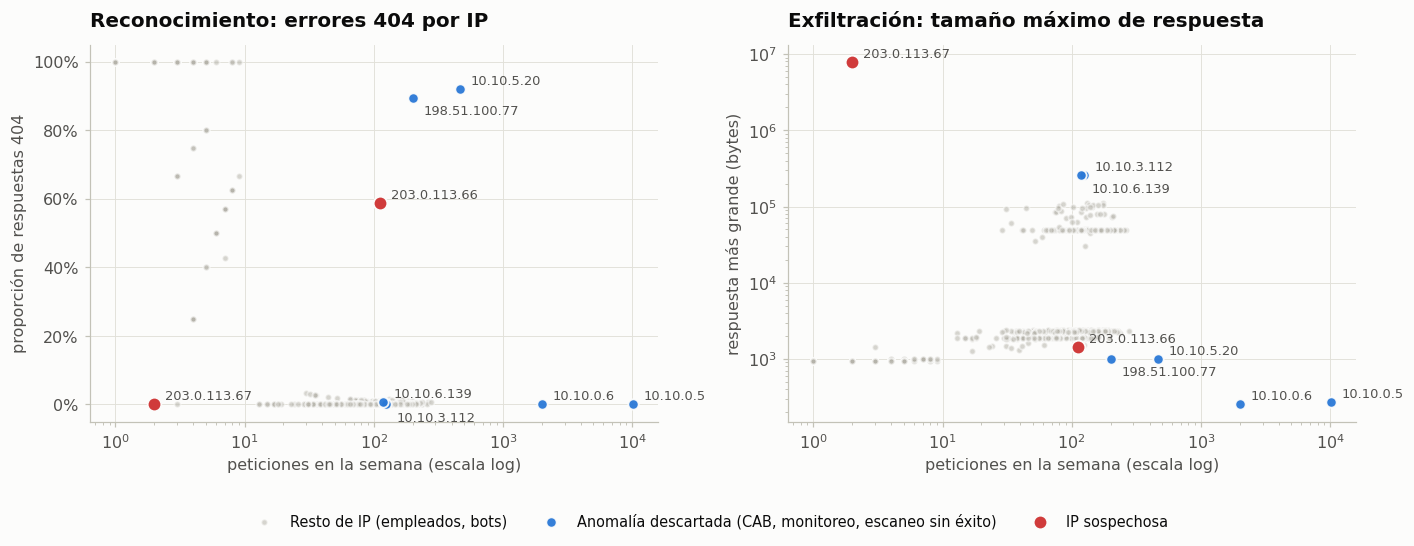

In [15]:
# Figura para la presentación: dónde cae cada IP en dos dimensiones clave
cat = perfil[['ip', 'zona', 'peticiones', 'tasa_404', 'max_bytes_respuesta']].copy()
# Anomalías descartadas que se discuten en la presentación: escaneos, monitoreo y las 2 exportaciones más grandes
exportadores = set(perfil[(perfil['zona'] == 'LAN') & ~perfil['ip'].isin(SOSPECHOSAS)].nlargest(2, 'max_bytes_respuesta')['ip'])
descartadas = (set(rafagas['ip']) | set(perfil.loc[perfil['zona'] == 'Monitoreo', 'ip']) | exportadores) - set(SOSPECHOSAS)
cat['grupo'] = np.where(cat['ip'].isin(SOSPECHOSAS), 'sospechosa', np.where(cat['ip'].isin(descartadas), 'descartada', 'otra'))
estilos = {'otra': (GRIS, 'Resto de IP (empleados, bots)', 16, 0.55),
           'descartada': (AZUL, 'Anomalía descartada (CAB, monitoreo, escaneo sin éxito)', 46, 0.95),
           'sospechosa': (CRITICO, 'IP sospechosa', 80, 1.0)}

def rotulos_sin_solape(ax, puntos):
    # Prueba varias posiciones alrededor de cada punto y usa la primera cuya caja no choca con otra
    r = ax.figure.canvas.get_renderer()
    cajas = []
    candidatos = [(7, 3, 'left'), (7, -11, 'left'), (-7, 3, 'right'), (-7, -11, 'right'), (7, 16, 'left'), (7, -24, 'left'), (-7, 16, 'right')]
    for x, yv, texto in sorted(puntos, key=lambda p: -ax.transData.transform((p[0], p[1]))[1]):
        for dx, dy, ha in candidatos:
            a = ax.annotate(texto, (x, yv), xytext=(dx, dy), textcoords='offset points', fontsize=8.5, color=TINTA2, ha=ha)
            caja = a.get_window_extent(r)
            if not any(caja.overlaps(c) for c in cajas):
                break
            a.remove()
        else:  # ninguna posición libre: se deja en la primera
            a = ax.annotate(texto, (x, yv), xytext=(7, 3), textcoords='offset points', fontsize=8.5, color=TINTA2)
            caja = a.get_window_extent(r)
        cajas.append(caja)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, (ycol, ytit) in zip(axs, [('tasa_404', 'proporción de respuestas 404'), ('max_bytes_respuesta', 'respuesta más grande (bytes)')]):
    for g in ['otra', 'descartada', 'sospechosa']:
        d = cat[cat['grupo'] == g]
        color, etiqueta, tam, alfa = estilos[g]
        ax.scatter(d['peticiones'], d[ycol], s=tam, color=color, alpha=alfa, edgecolor=FONDO, linewidth=1.2, label=etiqueta, zorder=3)
    ax.set_xscale('log'); ax.set_xlabel('peticiones en la semana (escala log)'); ax.set_ylabel(ytit)
    if ycol == 'max_bytes_respuesta':
        ax.set_yscale('log')
    else:
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.0%}'))
    fig.canvas.draw()
    rotulos_sin_solape(ax, [(f.peticiones, getattr(f, ycol), f.ip) for f in cat[cat['grupo'] != 'otra'].itertuples()])
axs[0].set_title('Reconocimiento: errores 404 por IP')
axs[1].set_title('Exfiltración: tamaño máximo de respuesta')
fig.legend(*axs[0].get_legend_handles_labels(), loc='lower center', ncol=3, fontsize=9.5, bbox_to_anchor=(0.5, -0.04))
fig.tight_layout(rect=(0, 0.06, 1, 1))
guardar(fig, 'fig03_ips_anomalas')

**¿Qué encontramos?** Cada punto es una IP. **A la izquierda**, la proporción de errores 404: los tres escáneres quedan arriba, y uno de ellos, `203.0.113.66`, está en rojo porque es el único escaneo sin explicación. **A la derecha**, la respuesta más grande que recibió cada IP: arriba del todo, sola, `203.0.113.67`, con **apenas un par de peticiones en toda la semana** pero la descarga más grande. Los puntos azules son las anomalías que el contexto explicó.

### 4.6 Cazar con patrones: firmas de ataque con expresiones regulares

**¿Qué buscamos?** Hasta aquí medimos **cuánto** hace cada IP (volumen, errores, bytes). Ahora miramos **qué escribe**: muchos ataques dejan texto característico en la dirección pedida o en el *User-Agent*. Una **firma** es una expresión regular que describe ese texto; así trabajan los detectores de intrusos (IDS) y las reglas de un SIEM.

**¿Cómo?** Pasamos siete firmas por **todas** las peticiones de la semana con `regexp_matches` de DuckDB y contamos cuántas coincidencias vienen de las dos IP que el triage dejó sin explicar y cuántas del resto.

| Firma | Dónde busca | Patrón |
|---|---|---|
| Rutas típicas de escáner | dirección | `(?i)/(\.env\|\.git/\|wp-login\.php\|phpmyadmin\|server-status\|backup\|db\.sql\|shell\.php\|config\.php)` |
| Herramienta de ataque | *User-Agent* | `(?i)(gobuster\|nikto\|sqlmap\|nmap\|dirbuster\|wpscan\|nuclei\|masscan\|zgrab)` |
| Cliente de línea de comandos | *User-Agent* | `^(curl\|python-requests\|Wget\|Go-http-client)/` |
| Programa PHP dentro de `/uploads` | dirección | `^/uploads/.*\.php$` |
| Parámetro en Base64 | parámetros | `[?&](x\|dl)=[A-Za-z0-9+/]{4,}={0,2}$` |
| Inyección SQL clásica | dirección y parámetros | `(?i)(union(\s\|%20\|\+)+select\|(\s\|%20)or(\s\|%20)+1=1\|%27--)` |
| Recorrido de directorios | dirección y parámetros | `(\.\./\|%2e%2e%2f)` |

Piezas nuevas: `(?i)` ignora mayúsculas y minúsculas; `\.` es un punto literal (sin la barra, `.` es «cualquier carácter»); `[A-Za-z0-9+/]` es el alfabeto de Base64; `{4,}` significa «4 o más»; `={0,2}` acepta el relleno final de Base64 (cero, uno o dos `=`).

firma,coincidencias,IP distintas,de IP sospechosas,del resto,precisión
Rutas típicas de escáner,150,63,27,123,18%
Herramienta de ataque,298,13,61,237,20%
Cliente de línea de comandos,267,58,53,214,20%
Programa PHP dentro de /uploads,34,2,34,0,100%
Parámetro en Base64,14,2,14,0,100%
Inyección SQL clásica,0,0,0,0,—
Recorrido de directorios,0,0,0,0,—


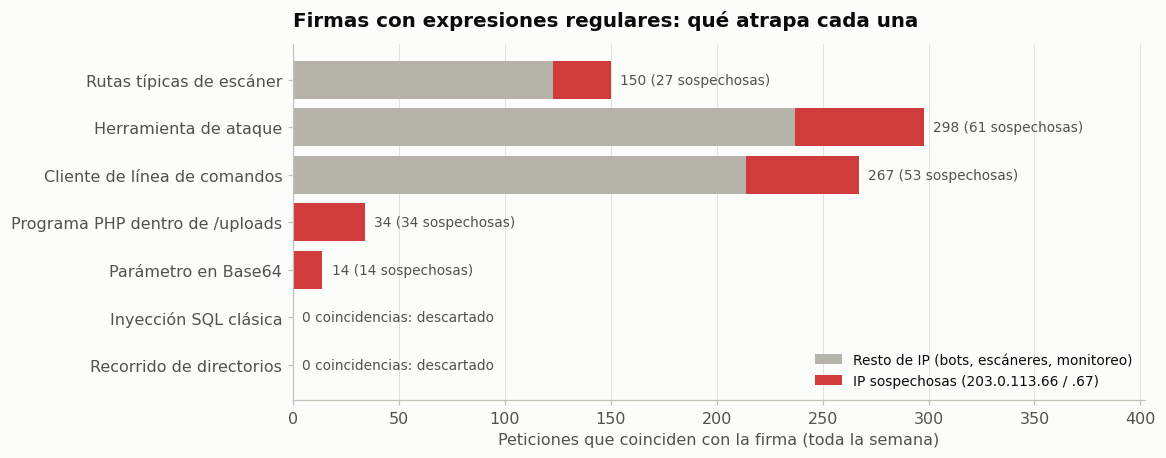

In [16]:
FIRMAS = [
    ('Rutas típicas de escáner', 'uri',
     r'(?i)/(\.env|\.git/|wp-login\.php|phpmyadmin|server-status|backup|db\.sql|shell\.php|config\.php)'),
    ('Herramienta de ataque', 'user_agent', r'(?i)(gobuster|nikto|sqlmap|nmap|dirbuster|wpscan|nuclei|masscan|zgrab)'),
    ('Cliente de línea de comandos', 'user_agent', r'^(curl|python-requests|Wget|Go-http-client)/'),
    ('Programa PHP dentro de /uploads', 'uri', r'^/uploads/.*\.php$'),
    ('Parámetro en Base64', "coalesce(query, '')", r'[?&](x|dl)=[A-Za-z0-9+/]{4,}={0,2}$'),
    ('Inyección SQL clásica', "uri || coalesce(query, '')", r'(?i)(union(\s|%20|\+)+select|(\s|%20)or(\s|%20)+1=1|%27--)'),
    ('Recorrido de directorios', "uri || coalesce(query, '')", r'(\.\./|%2e%2e%2f)'),
]
filas = []
for nombre, campo, patron in FIRMAS:
    r = con.sql(f'''
        SELECT COUNT(*) AS coincidencias,
               COUNT(DISTINCT client_ip) AS ips,
               COUNT(*) FILTER (WHERE list_contains($sos::VARCHAR[], client_ip)) AS de_ip_sospechosas,
               COUNT(DISTINCT client_ip) FILTER (WHERE list_contains($sos::VARCHAR[], client_ip)) AS ips_sospechosas
        FROM web WHERE regexp_matches({campo}, $p)
    ''', params={'p': patron, 'sos': list(SOSPECHOSAS)}).df().iloc[0]
    filas.append({'firma': nombre, 'coincidencias': int(r['coincidencias']), 'IP distintas': int(r['ips']),
                  'de IP sospechosas': int(r['de_ip_sospechosas']),
                  'del resto': int(r['coincidencias'] - r['de_ip_sospechosas']),
                  'precisión': (r['de_ip_sospechosas'] / r['coincidencias']) if r['coincidencias'] else None})
firmas = pd.DataFrame(filas)
display(firmas.style.format({'precisión': lambda v: '—' if pd.isna(v) else f'{v:.0%}'}).hide(axis='index'))

# Figura: de dónde vienen las coincidencias de cada firma
f = firmas.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.barh(f['firma'], f['del resto'], color=GRIS, label='Resto de IP (bots, escáneres, monitoreo)')
ax.barh(f['firma'], f['de IP sospechosas'], left=f['del resto'], color=CRITICO, label='IP sospechosas (203.0.113.66 / .67)')
for y, (tot, sos) in enumerate(zip(f['coincidencias'], f['de IP sospechosas'])):
    ax.annotate('0 coincidencias: descartado' if tot == 0 else f'{tot} ({sos} sospechosas)',
                (tot, y), xytext=(6, 0), textcoords='offset points', va='center', fontsize=9, color=TINTA2)
ax.set_title('Firmas con expresiones regulares: qué atrapa cada una')
ax.set_xlabel('Peticiones que coinciden con la firma (toda la semana)')
ax.set_xlim(0, firmas['coincidencias'].max() * 1.35)
ax.grid(axis='y', visible=False)
ax.legend(loc='lower right', fontsize=9)
guardar(fig, 'fig08_firmas_regex')

**¿Qué encontramos?** Las firmas se reparten en tres grupos, y cada uno enseña algo:

* **Las generales atrapan ruido.** «Rutas de escáner», «herramienta de ataque» y «cliente de línea de comandos» coinciden con **cientos** de peticiones, y unas **4 de cada 5** vienen de bots de Internet que pasan por cualquier portal. El atacante también aparece (usó `gobuster` y `python-requests`), pero mezclado con el ruido. Ayudan a filtrar; solas no señalan a nadie.
* **Las específicas atrapan solo al atacante.** «PHP dentro de `/uploads`» y «parámetro en Base64» tienen **precisión del 100 %**: todas sus coincidencias vienen de `203.0.113.66` y `203.0.113.67`. Una carpeta de fotos no debería servir programas, y nadie legítimo manda órdenes en Base64 por la URL.
* **Las que dan cero también informan.** No hubo inyección SQL ni recorrido de directorios: esos vectores quedan **descartados**.

**El límite.** Ninguna firma sobre la URL ve el exploit en sí: el campo `PHP_SESSION_UPLOAD_PROGRESS` viajaba en el **cuerpo** de las subidas, y el servidor web no guarda los cuerpos. Por eso la siguiente sección busca la entrada con otros rasgos: tamaño, errores 500 y caídas.

## 5. ¿Por dónde entró? (el vector de entrada)

### 5.1 Las subidas a la página de la foto de perfil

**¿Qué buscamos?** En la Parte I vimos que PHP2Shell se lanza con **subidas de archivo** enormes que incluyen el campo `PHP_SESSION_UPLOAD_PROGRESS`, y que los intentos fallidos producen **errores 500**. En el portal, la página que recibe archivos es la de **subir la foto de perfil** (`/empleados/foto.php`).

El problema: esa página recibe subidas **legítimas** todo el tiempo, de empleados que cambian su foto. Así que no basta con ver que «alguien subió algo». Comparamos las subidas normales con las demás según tres rasgos: **tamaño** (una foto pesa unos 50 KB), **si había sesión iniciada** y **si el servidor se cayó** (500).

In [17]:
PAGINA_SUBIDA = '/empleados/foto.php'
display(con.sql(f'''
    SELECT CASE WHEN status = 500 THEN 'ANÓMALA (servidor caído)'
                WHEN usuario IS NULL THEN 'sin autenticar'
                ELSE 'subida normal (empleado)' END AS tipo,
           COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips,
           quantile_cont(bytes_received, 0.5)::INT AS mediana_bytes, MAX(bytes_received) AS max_bytes
    FROM web WHERE uri = '{PAGINA_SUBIDA}' AND method = 'POST' GROUP BY 1 ORDER BY max_bytes DESC
''').df())

# Las subidas sospechosas: a la página de la foto, enormes y/o que tumbaron el servidor
posts = con.sql(f'''
    SELECT ts, client_ip, usuario, status, bytes_received, bytes_sent, user_agent, request_id
    FROM web
    WHERE uri = '{PAGINA_SUBIDA}' AND method = 'POST' AND (status = 500 OR bytes_received > 100000)
    ORDER BY ts
''').df()
print(f"{len(posts)} subidas anómalas, todas desde {posts['client_ip'].nunique()} IP sin autenticar:")
display(posts)

,tipo,peticiones,ips,mediana_bytes,max_bytes
0,sin autenticar,1,1,685699,685699
1,ANÓMALA (servidor caído),18,1,543199,670699
2,subida normal (empleado),192,165,50069,50085


19 subidas anómalas, todas desde 1 IP sin autenticar:


,ts,client_ip,usuario,status,bytes_received,bytes_sent,user_agent,request_id
0,2026-11-06 01:52:09.000,203.0.113.66,None,500,415699,211,python-requests/2.32.3,avtoH3qL9OLdEISYh1q6bAAAABY
1,2026-11-06 01:52:21.500,203.0.113.66,None,500,430699,211,python-requests/2.32.3,avtoHxnQNlWGoooo-rVAGwAAAAU
2,2026-11-06 01:52:34.000,203.0.113.66,None,500,445699,211,python-requests/2.32.3,avtoH92cEVbeQiQDoB0GHwAAABI
3,2026-11-06 01:52:46.500,203.0.113.66,None,500,460699,211,python-requests/2.32.3,avtoH_xU9MJq02gmPWkJBQAAAAI
4,2026-11-06 01:52:59.000,203.0.113.66,None,500,475699,211,python-requests/2.32.3,avtoH-fXYZtWKDiOcfuk5AAAAAo
5,2026-11-06 01:53:11.500,203.0.113.66,None,500,490699,211,python-requests/2.32.3,avtoH6Eiy-iekTsqp88-TAAAAAs
6,2026-11-06 01:53:24.000,203.0.113.66,None,500,505699,211,python-requests/2.32.3,avtoH21hUUd86mnZZLAfIgAAABw
7,2026-11-06 01:53:36.500,203.0.113.66,None,500,520699,211,python-requests/2.32.3,avtoH9yJlYbhmxg-l0zjNQAAAAw
8,2026-11-06 01:53:49.000,203.0.113.66,None,500,535699,211,python-requests/2.32.3,avtoH5TaQg8BrvtiFWtC_gAAAA4
9,2026-11-06 01:54:01.500,203.0.113.66,None,500,550699,211,python-requests/2.32.3,avtoHx_eqJORQB2IIEVASgAAABs


**¿Qué encontramos?**

* **192 subidas normales** de 165 empleados distintos, todas con sesión iniciada y de unos **50 KB**: gente cambiando su foto.
* Un grupo de **subidas anómalas**, todas de **una sola IP** (`203.0.113.66`), **sin sesión iniciada**, de **varios cientos de KB** cada una (más de 10 veces una foto), y **todas menos la última tumbaron el servidor** (500).
* La herramienta que las envió se identifica como `python-requests`: un **programa**, no un navegador.

¿Cómo puede alguien sin sesión subir algo a una página que exige iniciar sesión? Porque, como vimos en la Parte I, **PHP procesa el archivo antes** de que el código del portal revise la sesión. Esto es exactamente lo que predice PHP2Shell: **muchos fallos y, al final, un acierto**.

### 5.2 ¿Esas subidas tumbaron el servidor? Unir dos registros por la hora

**¿Qué buscamos?** El registro de la aplicación anota cada vez que un proceso de Apache muere (`AH00052 Segmentation fault`), pero **no dice qué visita lo provocó**: el proceso murió antes de poder contarlo. Para saberlo, hay que unir dos registros distintos **usando solo la hora**.

**¿Cómo?** Para cada caída buscamos **la última petición que llegó justo antes**. Es como cruzar la hora de un apagón con el registro de quién conectó qué aparato en ese momento. En SQL esta operación se llama `ASOF JOIN` («unir con el más cercano anterior»).

In [18]:
caidas = con.sql('''
    WITH c AS (SELECT ts, message FROM app WHERE event = 'child_crash'),
         w AS (SELECT ts AS ts_peticion, client_ip, method, uri, status, bytes_received FROM web)
    SELECT c.ts AS ts_caida, c.message, w.ts_peticion,
           ROUND(epoch(c.ts - w.ts_peticion) * 1000)::INT AS ms_despues,
           w.client_ip, w.method, w.uri, w.status, w.bytes_received
    FROM c ASOF JOIN w ON c.ts >= w.ts_peticion
    ORDER BY c.ts
''').df()
display(caidas)
ips_caidas = ', '.join(caidas['client_ip'].dropna().unique())
print(f"{len(caidas)} caídas; cada una ocurre justo después de una subida a {caidas['uri'].mode()[0]} "
      f"desde {ips_caidas} (máximo {caidas['ms_despues'].max()} ms de diferencia).")

,ts_caida,message,ts_peticion,ms_despues,client_ip,method,uri,status,bytes_received
0,2026-11-06 01:52:09.000,AH00052: child pid 2287 exit signal Segmentation fault (11),2026-11-06 01:52:09.000,0,203.0.113.66,POST,/empleados/foto.php,500,415699
1,2026-11-06 01:52:21.513,AH00052: child pid 2295 exit signal Segmentation fault (11),2026-11-06 01:52:21.500,13,203.0.113.66,POST,/empleados/foto.php,500,430699
2,2026-11-06 01:52:34.000,AH00052: child pid 5895 exit signal Segmentation fault (11),2026-11-06 01:52:34.000,0,203.0.113.66,POST,/empleados/foto.php,500,445699
3,2026-11-06 01:52:46.500,AH00052: child pid 7754 exit signal Segmentation fault (11),2026-11-06 01:52:46.500,0,203.0.113.66,POST,/empleados/foto.php,500,460699
4,2026-11-06 01:52:59.000,AH00052: child pid 7901 exit signal Segmentation fault (11),2026-11-06 01:52:59.000,0,203.0.113.66,POST,/empleados/foto.php,500,475699
5,2026-11-06 01:53:11.500,AH00052: child pid 4712 exit signal Segmentation fault (11),2026-11-06 01:53:11.500,0,203.0.113.66,POST,/empleados/foto.php,500,490699
6,2026-11-06 01:53:24.000,AH00052: child pid 6574 exit signal Segmentation fault (11),2026-11-06 01:53:24.000,0,203.0.113.66,POST,/empleados/foto.php,500,505699
7,2026-11-06 01:53:36.500,AH00052: child pid 6870 exit signal Segmentation fault (11),2026-11-06 01:53:36.500,0,203.0.113.66,POST,/empleados/foto.php,500,520699
8,2026-11-06 01:53:49.000,AH00052: child pid 5893 exit signal Segmentation fault (11),2026-11-06 01:53:49.000,0,203.0.113.66,POST,/empleados/foto.php,500,535699
9,2026-11-06 01:54:01.500,AH00052: child pid 4267 exit signal Segmentation fault (11),2026-11-06 01:54:01.500,0,203.0.113.66,POST,/empleados/foto.php,500,550699


18 caídas; cada una ocurre justo después de una subida a /empleados/foto.php desde 203.0.113.66 (máximo 13 ms de diferencia).


**¿Qué encontramos?** **Cada una** de las caídas ocurre **pocos milisegundos después** de una subida de `203.0.113.66` a la página de la foto. Que pase una vez podría ser casualidad; que pase **en todas** no lo es. Ahora tenemos dos fuentes independientes que cuentan la misma historia.

### 5.3 Aparece un programa donde solo debería haber fotos

**¿Qué buscamos?** Si el intento 19 tuvo éxito, el atacante debió dejar algo en el servidor. Para eso está el **monitor de integridad de archivos (FIM)**: un vigilante que lleva el inventario de los archivos del servidor y anota cada archivo que **aparece, cambia o desaparece**, con su huella SHA-256 y su dueño. En la carpeta de fotos solo deberían aparecer imágenes `.png`/`.jpg`.

Una **webshell** es un pequeño programa que el atacante deja en el servidor como **puerta trasera**: una página web que, en vez de mostrar contenido, **obedece las órdenes** que se le escriben en la dirección (URL). Así puede volver cuando quiera sin repetir el exploit.

También revisamos cuándo se visitó ese archivo por primera vez y si hay otras páginas `.php` que «nacieron» a mitad de semana.

In [19]:
fim_php = con.sql("SELECT ts, event, path, size, sha256, owner, mode FROM fim WHERE path LIKE '%.php' ORDER BY ts").df()
display(fim_php)
print('Eventos FIM de archivos de imagen (fotos de perfil legítimas):',
      con.sql("SELECT COUNT(*) FROM fim WHERE path NOT LIKE '%.php'").fetchone()[0])

WEBSHELL = fim_php.iloc[0]['path'].replace('/var/www/html', '')
T_IMPLANTE = fim_php.iloc[0]['ts']

ultimo_post = posts[posts['ts'] <= T_IMPLANTE].iloc[-1]
primer_200 = con.sql('SELECT MIN(ts) FROM web WHERE uri = ? AND status = 200', params=[WEBSHELL]).fetchone()[0]
previos_404 = con.sql('SELECT COUNT(*) FROM web WHERE uri = ? AND status = 404', params=[WEBSHELL]).fetchone()[0]

uris_nuevas = con.sql('''
    SELECT uri, MIN(ts) AS primera_vez, COUNT(*) AS peticiones, COUNT(DISTINCT client_ip) AS ips,
           list(DISTINCT client_ip) AS lista_ips
    FROM web WHERE status = 200 AND uri LIKE '%.php'
    GROUP BY uri
    HAVING MIN(ts) > (SELECT MIN(ts) FROM web) + INTERVAL 1 DAY   -- URI que "nace" a mitad de la semana
    ORDER BY primera_vez
''').df()
display(uris_nuevas)

display(Markdown(f'''
* **Último POST explotador** (no devolvió 500): `{ultimo_post.ts}` desde **{ultimo_post.client_ip}** (`{ultimo_post.user_agent}`), {num(ultimo_post.bytes_received)} bytes de cuerpo.
* **Creación de la webshell (FIM):** `{T_IMPLANTE}` → `{fim_php.iloc[0]['path']}` (propietario `{fim_php.iloc[0]['owner']}`, SHA-256 `{fim_php.iloc[0]['sha256'][:16]}…`), **{(T_IMPLANTE - ultimo_post.ts).total_seconds() * 1000:.0f} ms** después del POST.
* Antes de eso, el atacante consultó **{previos_404} veces** `{WEBSHELL}` y recibió 404: estaba esperando a que el exploit funcionara. **Primer 200:** `{primer_200}`.
* Es la única URI `.php` que empezó a responder 200 a mitad de la semana (no existía antes): es el artefacto del ataque.
'''))

,ts,event,path,size,sha256,owner,mode
0,2026-11-06 01:55:54,file_added,/var/www/html/uploads/avatars/thumb_8f3a.php,207,a0a401e8e0260ef38cb542a3c867cb717d66b364bdecb99cc81182522e153c1e,www-data,0644


Eventos FIM de archivos de imagen (fotos de perfil legítimas): 192


,uri,primera_vez,peticiones,ips,lista_ips
0,/uploads/avatars/thumb_8f3a.php,2026-11-06 01:55:54.500,16,2,"[203.0.113.66, 203.0.113.67]"



* **Último POST explotador** (no devolvió 500): `2026-11-06 01:55:54` desde **203.0.113.66** (`python-requests/2.32.3`), 685.699 bytes de cuerpo.
* **Creación de la webshell (FIM):** `2026-11-06 01:55:54` → `/var/www/html/uploads/avatars/thumb_8f3a.php` (propietario `www-data`, SHA-256 `a0a401e8e0260ef3…`), **0 ms** después del POST.
* Antes de eso, el atacante consultó **18 veces** `/uploads/avatars/thumb_8f3a.php` y recibió 404: estaba esperando a que el exploit funcionara. **Primer 200:** `2026-11-06 01:55:54.500000`.
* Es la única URI `.php` que empezó a responder 200 a mitad de la semana (no existía antes): es el artefacto del ataque.


**¿Por qué esto es tan contundente?** Son tres fuentes distintas, que no se comunican entre sí, coincidiendo al milisegundo: el **servidor web** registra la subida número 19, el **FIM** registra un archivo `.php` nuevo en la carpeta de fotos **instantes después**, y luego el servidor web registra al atacante **usando** ese archivo. Además, el atacante lo había pedido varias veces antes y recibía 404: **estaba esperando a que el exploit funcionara**. Respondimos el **¿dónde?**: entró por `/empleados/foto.php` y dejó `/uploads/avatars/thumb_8f3a.php`.

## 6. ¿Qué hizo una vez adentro? (post-explotación)

**¿Qué buscamos?** Las órdenes que el atacante le dio a la webshell.

**¿Cómo?** El atacante escribía cada orden en la URL, en el parámetro `x`, **codificada en Base64**. Base64 **no es cifrado**: es solo otra forma de escribir el mismo texto, con letras y números, para que pase por filtros simples sin llamar la atención. Por ejemplo, `whoami` se escribe `d2hvYW1p`. Se convierte de vuelta sin ninguna clave. Como el servidor web anota la URL completa de cada visita, **las órdenes quedaron escritas en el registro** y basta con decodificarlas.

A cada orden le asignamos su técnica en **MITRE ATT&CK**, el catálogo mundial de técnicas de atacantes. Es un idioma común: decir «T1552.001» le dice a cualquier analista del mundo «buscó contraseñas guardadas en archivos». Por seguridad, las contraseñas que aparecen dentro de las órdenes se muestran tapadas (`********`).

In [20]:
ws = con.sql('''
    SELECT ts, client_ip, user_agent, query, status, bytes_sent, request_id
    FROM web WHERE uri = ? AND status = 200 ORDER BY ts
''', params=[WEBSHELL]).df()

def decodificar(query):
    q = parse_qs((query or '').lstrip('?'))
    for clave, tipo in (('x', 'orden'), ('dl', 'descarga')):
        if clave in q:
            try:
                return tipo, base64.b64decode(q[clave][0]).decode('utf-8', 'replace')
            except Exception:
                return tipo, '<no decodificable>'
    return 'acceso', ''

ws[['tipo', 'orden']] = ws['query'].apply(lambda q: pd.Series(decodificar(q)))
ws['orden_segura'] = ws['orden'].str.replace(r"-p'[^']*'", "-p'********'", regex=True)  # no mostrar contraseñas

MITRE = [
    (r'^(id|whoami|hostname|uname|pwd|php -v)', 'T1082 Descubrimiento de información del sistema'),
    (r'^ls ', 'T1083 Descubrimiento de archivos y directorios'),
    (r'^cat .*config', 'T1552.001 Credenciales en archivos'),
    (r'^mysql .*(SHOW TABLES|COUNT)', 'T1078 Cuentas válidas (BD) + reconocimiento de tablas'),
    (r'^mysql .*SELECT \*', 'T1005 Datos del sistema local (volcado de tablas)'),
    (r'^mkdir', 'T1074.001 Preparación de datos en local'),
    (r'^(tar|du)', 'T1560.001 Compresión de datos para exfiltrar'),
    (r'^/tmp/', 'T1041 Exfiltración por el canal de C2 (descarga HTTP)'),
    (r'^rm ', 'T1070.004 Borrado de archivos (antiforense)'),
]
ws['mitre'] = ws['orden'].apply(lambda o: next((t for p, t in MITRE if re.search(p, o)), 'T1505.003 Webshell (acceso)'))
pd.set_option('display.max_colwidth', 95)
display(ws[['ts', 'client_ip', 'user_agent', 'tipo', 'orden_segura', 'bytes_sent', 'mitre']].style
        .format({'bytes_sent': '{:,}'}).hide(axis='index'))

ts,client_ip,user_agent,tipo,orden_segura,bytes_sent,mitre
2026-11-06 01:55:54.500000,203.0.113.66,python-requests/2.32.3,acceso,,230,T1505.003 Webshell (acceso)
2026-11-06 01:56:09.500000,203.0.113.66,python-requests/2.32.3,orden,id,285,T1082 Descubrimiento de información del sistema
2026-11-06 01:56:24.500000,203.0.113.66,python-requests/2.32.3,orden,php -v,400,T1082 Descubrimiento de información del sistema
2026-11-06 01:56:39.500000,203.0.113.66,python-requests/2.32.3,orden,cat /var/www/html/config/database.php,555,T1552.001 Credenciales en archivos
2026-11-06 01:56:54.500000,203.0.113.66,python-requests/2.32.3,orden,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SELECT * FROM clientes ORDER BY id LIMIT 10 OFFSET 0""","1,432",T1005 Datos del sistema local (volcado de tablas)
2026-11-06 01:57:09.500000,203.0.113.66,python-requests/2.32.3,orden,mkdir -p /tmp/.d,230,T1074.001 Preparación de datos en local
2026-11-06 01:57:24.500000,203.0.113.66,python-requests/2.32.3,orden,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 0"" > /tmp/.d/clientes_0.tsv",230,T1005 Datos del sistema local (volcado de tablas)
2026-11-06 01:57:39.500000,203.0.113.66,python-requests/2.32.3,orden,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 500"" > /tmp/.d/clientes_1.tsv",230,T1005 Datos del sistema local (volcado de tablas)
2026-11-06 01:57:54.500000,203.0.113.66,python-requests/2.32.3,orden,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 1000"" > /tmp/.d/clientes_2.tsv",230,T1005 Datos del sistema local (volcado de tablas)
2026-11-06 01:58:09.500000,203.0.113.66,python-requests/2.32.3,orden,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 1500"" > /tmp/.d/clientes_3.tsv",230,T1005 Datos del sistema local (volcado de tablas)


**¿Qué encontramos?** La secuencia completa de lo que hizo el atacante, en orden:

1. **Reconoció dónde estaba**: órdenes como `id` o `php -v` (quién soy, qué máquina es esta).
2. **Buscó contraseñas**: leyó `config/database.php`, el archivo con las contraseñas de la base de datos.
3. **Entró a la base de datos** con la cuenta de mantenimiento `techcorp_admin` y tanteó las tablas.
4. **Preparó el robo**: creó una carpeta oculta `/tmp/.d` y guardó allí las tablas de **clientes** (en 4 bloques de 500) y **empleados**.
5. **Empaquetó** todo en dos archivos comprimidos y los **descargó desde otra IP** (`203.0.113.67`).
6. **Borró sus huellas** con `rm -rf`. Esto es **antiforense**: destruir evidencia.

Pero la orden de borrar **también quedó anotada**. Intentar ocultar algo es, en sí mismo, una prueba.

> **Expresión regular en uso: clasificar y proteger.** La celda anterior usó expresiones regulares de dos maneras:
>
> * **Para clasificar.** Cada técnica de MITRE ATT&CK tiene un patrón; la primera que coincide con la orden le pone la etiqueta. `^` obliga a que la orden **empiece** así (`^rm ` no confunde `rm` con `firmware`), `|` significa «o» (`^(tar|du)`) y `.*` acepta cualquier cosa en medio (`^cat .*config`).
> * **Para proteger.** `-p'[^']*'` encuentra la contraseña que va después de `-p` entre comillas y la reemplaza por `********`. La evidencia no se modifica: solo cambia lo que se **muestra**.
>
> La tabla siguiente comprueba cada patrón contra todas las órdenes: cuántas atrapó y cuáles.

In [21]:
comprobacion = pd.DataFrame([
    {'patrón': p, 'técnica': t,
     'órdenes que coinciden': int(ws['orden'].map(lambda o: bool(re.search(p, o))).sum()),
     'ejemplo': next(iter(ws.loc[ws['orden'].map(lambda o: bool(re.search(p, o))), 'orden_segura'].str[:70]), '—')}
    for p, t in MITRE])
display(comprobacion.style.hide(axis='index'))
ver_regex(r'^cat .*config', ws.loc[ws['orden'].str.startswith('cat '), 'orden'].iloc[0], 'robo de credenciales (T1552.001)')

patrón,técnica,órdenes que coinciden,ejemplo
^(id|whoami|hostname|uname|pwd|php -v),T1082 Descubrimiento de información del sistema,2,id
^ls,T1083 Descubrimiento de archivos y directorios,0,—
^cat .*config,T1552.001 Credenciales en archivos,1,cat /var/www/html/config/database.php
^mysql .*(SHOW TABLES|COUNT),T1078 Cuentas válidas (BD) + reconocimiento de tablas,0,—
^mysql .*SELECT \*,T1005 Datos del sistema local (volcado de tablas),6,"mysql -h db -u techcorp_admin -p'********' techcorp -e ""SELECT * FROM"
^mkdir,T1074.001 Preparación de datos en local,1,mkdir -p /tmp/.d
^(tar|du),T1560.001 Compresión de datos para exfiltrar,2,tar czf /tmp/.d.tgz -C /tmp .d
^/tmp/,T1041 Exfiltración por el canal de C2 (descarga HTTP),2,/tmp/.d.tgz
^rm,T1070.004 Borrado de archivos (antiforense),1,rm -rf /tmp/.d /tmp/.d.tgz /tmp/.w.tgz


**robo de credenciales (T1552.001)**

### 6.1 Lo que el atacante borró… y lo que sabemos de ello

**¿Qué buscamos?** Esta es la pregunta central del trabajo: el atacante borró los archivos con los datos robados, así que **en el servidor ya no existen**. ¿Podemos saber igual qué contenían, cuándo se crearon, cuánto pesaban y cuándo desaparecieron?

**¿Cómo?** Solo con las órdenes decodificadas en el paso anterior. Cada orden que crea un archivo (`mysql … > archivo`, `tar czf archivo`, `mkdir`), lo descarga (`dl=`) o lo borra (`rm`) deja un registro con su hora. Reconstruimos la «vida» de cada archivo sin haberlo visto nunca.

> **Expresión regular en uso: leer las órdenes como datos.** Para saber qué archivo creó cada orden, la desarmamos con dos patrones:
>
> | Patrón | Grupos que captura | Ejemplo |
> |---|---|---|
> | `"SELECT \* FROM (\w+)[^"]*?(?:LIMIT (\d+) OFFSET (\d+))?" > (\S+)$` | 1 tabla · 2 límite · 3 desde qué fila · 4 archivo de destino | `… "SELECT * FROM clientes … LIMIT 500 OFFSET 0" > /tmp/.d/clientes_0.tsv` |
> | `tar czf (\S+) (?:-C (\S+) )?(\S+)$` | 1 archivo comprimido · 2 carpeta base (opcional) · 3 qué se comprimió | `tar czf /tmp/.d.tgz -C /tmp .d` |
>
> Piezas nuevas: `\*` es un asterisco **literal** (sin la barra, `*` significaría «repetir»); `\w+` es una palabra (el nombre de la tabla); `\d+` un número; `\S+` todo lo que no sea espacio (una ruta); `(?: … )?` agrupa una parte **opcional** sin capturarla; `$` obliga a que el texto termine ahí.

In [22]:
# Vida de cada archivo temporal del atacante, reconstruida SOLO con el registro del servidor web
vida = {}
def anotar(ruta, **datos):
    vida.setdefault(ruta, {'archivo': ruta}).update({k: v for k, v in datos.items() if k not in vida.get(ruta, {})})

for _, f in ws[ws['tipo'] != 'acceso'].iterrows():
    orden, hora = f['orden'], f['ts']
    if f['tipo'] == 'descarga':
        anotar(orden, descargado=hora, bytes_descargados=f['bytes_sent'], descargado_por=f['client_ip'])
    elif m := re.search(r'"SELECT \* FROM (\w+)[^"]*?(?:LIMIT (\d+) OFFSET (\d+))?" > (\S+)$', orden):
        tabla, lim, off, ruta = m.groups()
        contenido = f'tabla {tabla}' + (f' (filas {int(off) + 1}–{int(off) + int(lim)})' if lim else ' (completa)')
        anotar(ruta, contenido=contenido, creado=hora)
    elif m := re.match(r'tar czf (\S+) (?:-C (\S+) )?(\S+)$', orden):
        origen = f"{m.group(2)}/{m.group(3)}" if m.group(2) else m.group(3)
        anotar(m.group(1), contenido=f'comprimido de {origen}', creado=hora)
    elif orden.startswith('mkdir '):
        anotar(orden.split()[-1], contenido='carpeta oculta de preparación', creado=hora)
    elif orden.startswith('rm '):
        borradas = orden.split()[2:]
        for ruta in list(vida):
            if any(ruta == b or ruta.startswith(b + '/') for b in borradas):
                vida[ruta]['borrado'] = hora

borrados = pd.DataFrame(vida.values()).sort_values('creado')
borrados['¿existe hoy?'] = np.where(borrados['borrado'].notna(), 'No: borrado por el atacante', 'Sí')
display(borrados[['archivo', 'contenido', 'creado', 'descargado', 'descargado_por', 'bytes_descargados', 'borrado', '¿existe hoy?']]
        .style.format({'bytes_descargados': lambda b: '' if pd.isna(b) else mb(b),
                       'creado': '{:%H:%M:%S}', 'borrado': '{:%H:%M:%S}',
                       'descargado': lambda t: '' if pd.isna(t) else f'{t:%H:%M:%S}', 'descargado_por': lambda v: v if isinstance(v, str) else ''})
        .hide(axis='index'))

mismas = ws[ws['orden'] == 'ls -la /tmp/.d']
if len(mismas) >= 2:
    antes_, despues_ = mismas.iloc[0], mismas.iloc[-1]
    print(f"La orden «ls -la /tmp/.d» aparece dos veces: a las {antes_['ts']:%H:%M:%S} devolvió {num(antes_['bytes_sent'])} bytes (el listado con los archivos) "
          f"y a las {despues_['ts']:%H:%M:%S}, después del borrado, solo {num(despues_['bytes_sent'])}: el atacante comprobó que la carpeta ya no existía.")

archivo,contenido,creado,descargado,descargado_por,bytes_descargados,borrado,¿existe hoy?
/tmp/.d,carpeta oculta de preparación,01:57:09,,,,02:00:31,No: borrado por el atacante
/tmp/.d/clientes_0.tsv,tabla clientes (filas 1–500),01:57:24,,,,02:00:31,No: borrado por el atacante
/tmp/.d/clientes_1.tsv,tabla clientes (filas 501–1000),01:57:39,,,,02:00:31,No: borrado por el atacante
/tmp/.d/clientes_2.tsv,tabla clientes (filas 1001–1500),01:57:54,,,,02:00:31,No: borrado por el atacante
/tmp/.d/clientes_3.tsv,tabla clientes (filas 1501–2000),01:58:09,,,,02:00:31,No: borrado por el atacante
/tmp/.d/empleados.tsv,tabla empleados (completa),01:58:24,,,,02:00:31,No: borrado por el atacante
/tmp/.d.tgz,comprimido de /tmp/.d,01:58:39,01:59:35,203.0.113.67,"0,16 MB",02:00:31,No: borrado por el atacante
/tmp/.w.tgz,comprimido de /var/www/html,01:58:54,02:00:16,203.0.113.67,"7,52 MB",02:00:31,No: borrado por el atacante


In [23]:
# Los dos patrones sobre órdenes reales del atacante (con la contraseña ya tapada)
orden_volcado = ws.loc[ws['orden_segura'].str.contains(r'> /tmp/\S+$', regex=True), 'orden_segura'].iloc[0]
ver_regex(r'"SELECT \* FROM (\w+)[^"]*?(?:LIMIT (\d+) OFFSET (\d+))?" > (\S+)$', orden_volcado,
          'volcado de una tabla: tabla, límite, desde qué fila y archivo de destino')
orden_tar = ws.loc[ws['orden'].str.startswith('tar '), 'orden'].iloc[0]
ver_regex(r'tar czf (\S+) (?:-C (\S+) )?(\S+)$', orden_tar, 'compresión: archivo, carpeta base y qué se comprimió')

**volcado de una tabla: tabla, límite, desde qué fila y archivo de destino**

coincidencia,grupo,capturó
1,1,clientes
1,2,500
1,3,0
1,4,/tmp/.d/clientes_0.tsv


**compresión: archivo, carpeta base y qué se comprimió**

coincidencia,grupo,capturó
1,1,/tmp/.d.tgz
1,2,/tmp
1,3,.d


**¿Qué encontramos?** Ninguno de estos archivos existe hoy en el servidor y, sin embargo, sabemos de cada uno:

* **Qué contenía**: las 2000 filas de clientes en cuatro bloques, la tabla completa de empleados y, además, una copia comprimida de **todo el código del portal** (con las fotos de los empleados y el archivo de contraseñas).
* **Cuándo se creó, cuándo salió y cuándo se borró**, al segundo.
* **Cuánto pesaba lo que salió** y **hacia qué IP**.

Esa es la respuesta a la pregunta del trabajo: **borrar los archivos del servidor no borra lo que otros sistemas ya anotaron**. Por eso, en la vida real, los registros deben enviarse **en el momento** a un servidor aparte (un SIEM), donde el atacante no pueda alcanzarlos.

## 7. ¿Qué datos exactamente? (unir el servidor web con la base de datos)

**¿Qué buscamos?** Saber **qué consultas** hizo el atacante a la base de datos y **qué filas** le devolvió cada una. Para eso hay que unir dos registros: el del servidor web (quién pidió qué) y el de la base de datos (qué consulta se ejecutó).

**¿Cómo?** Cada visita al portal recibe un **número de seguimiento** único (`request_id`), como el número de guía de un envío. El portal escribe ese número dentro de cada consulta SQL que hace, en un comentario: `/*request_id='…',route='…'*/`. Esta práctica se llama *sqlcommenter*. Así, en la auditoría de la base de datos, cada consulta dice **qué visita la causó**. Extraemos ese número con una expresión regular y unimos las dos fuentes.

Primero vemos qué **cuentas de base de datos** se usaron en la semana.

> **Expresión regular en uso: la llave del caso.** Cada consulta SQL del portal lleva al final un comentario con el número de seguimiento de la petición web que la provocó (*sqlcommenter*):
>
> `SELECT … FROM clientes … /*request_id='avtHH0rIKu1KPmYJyqwPLQAAAAI',route='/uploads/avatars/thumb_8f3a.php'*/`
>
> Es texto libre dentro de otro texto. Para convertirlo en una columna con la que se pueda **unir** la auditoría de la base de datos con el servidor web, usamos `regexp_extract` con este patrón:
>
> | Pieza | Significa |
> |---|---|
> | `request_id='` | el texto literal que anuncia el identificador |
> | `(` … `)` | **grupo de captura**: la parte que queremos sacar (el `1` de `regexp_extract(…, 1)`) |
> | `[^']` | cualquier carácter **menos** una comilla |
> | `+` | uno o más de ellos: avanza hasta la comilla que cierra |
> | `'` | la comilla de cierre |
>
> En SQL la comilla se escribe doble (`''`) dentro de un texto; por eso en el código aparece `request_id=''([^'']+)''`. El mismo truco saca la ruta (`route='([^']+)'`).

In [24]:
PATRON_ID = "request_id=''([^'']+)''"     # comillas dobladas = comilla literal en SQL
PATRON_RUTA = "route=''([^'']+)''"
con.execute(f'''
    CREATE OR REPLACE TABLE db_c AS
    SELECT *, regexp_extract(sqltext, '{PATRON_ID}', 1)   AS request_id,
              regexp_extract(sqltext, '{PATRON_RUTA}', 1) AS ruta
    FROM db
''')
display(con.sql('''
    SELECT db_user, COUNT(*) AS sentencias, COUNT(DISTINCT ruta) AS rutas, MIN(ts) AS primera, MAX(ts) AS ultima,
           SUM(rows_sent) AS filas_leidas, list(DISTINCT ruta)[:4] AS ejemplos_de_ruta
    FROM db_c GROUP BY 1 ORDER BY 2 DESC
''').df())

,db_user,sentencias,rutas,primera,ultima,filas_leidas,ejemplos_de_ruta
0,techcorp_app,88502,15,2026-11-03 00:00:01.405,2026-11-10 01:42:40.083,387019.0,"[/api/health.php, /dashboard.php, /tickets/nuevo.php, /tickets/]"
1,techcorp_admin,6,1,2026-11-06 01:56:54.503,2026-11-06 01:58:24.505,2510.0,[/uploads/avatars/thumb_8f3a.php]


In [25]:
# El patrón, aplicado en vivo a una consulta real de la cuenta de mantenimiento
ejemplo_sql = con.sql("SELECT sqltext FROM db_c WHERE db_user = 'techcorp_admin' ORDER BY ts LIMIT 1").fetchone()[0]
ver_regex(r"request_id='([^']+)'", ejemplo_sql, 'request_id → la llave para unir con el servidor web')
ver_regex(r"route='([^']+)'", ejemplo_sql, 'route → qué página del portal hizo la consulta')

**request_id → la llave para unir con el servidor web**

coincidencia,grupo,capturó
1,1,avtoH21hUUd86mnZZLAfJQAAABw


**route → qué página del portal hizo la consulta**

coincidencia,grupo,capturó
1,1,/uploads/avatars/thumb_8f3a.php


**¿Qué vemos?** En amarillo, lo que atrapa cada patrón; en la tabla, el **grupo de captura**: el valor limpio que queda en la columna. Ese `request_id` es el mismo que Apache anotó en el registro web, así que ahora una consulta a la base de datos y una visita al portal se pueden unir como dos tablas cualquiera. Con eso respondemos «¿qué IP pidió qué fila?».

**¿Qué encontramos? Una escalada de privilegios.** El portal tiene dos cuentas para entrar a la base de datos:

* `techcorp_app`: la del día a día, con **permisos mínimos** (no puede borrar tablas, por ejemplo). Hizo más de 88 000 consultas en la semana.
* `techcorp_admin`: una cuenta vieja de **mantenimiento**, con **todos los permisos**, cuya contraseña quedó olvidada en `config/database.php`.

La cuenta `techcorp_admin` **no se usó en toda la semana**, salvo unos minutos en la madrugada del viernes, **solo desde la webshell** y justo después de que el atacante leyera ese archivo. El gráfico siguiente lo muestra.

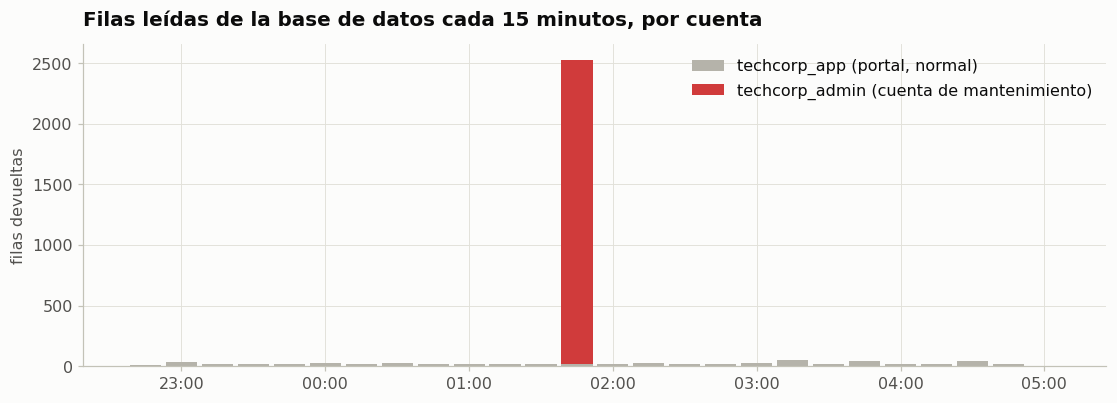

In [26]:
filas_hora = con.sql('''
    SELECT time_bucket(INTERVAL 15 MINUTE, ts) AS t, db_user, SUM(rows_sent) AS filas
    FROM db_c WHERE ts BETWEEN (SELECT MIN(ts) FROM web WHERE client_ip LIKE '203.0.113.%') - INTERVAL 3 HOUR
                           AND (SELECT MAX(ts) FROM web WHERE client_ip LIKE '203.0.113.%') + INTERVAL 3 HOUR
    GROUP BY ALL ORDER BY 1
''').df().pivot_table(index='t', columns='db_user', values='filas', fill_value=0)

fig, ax = plt.subplots(figsize=(12, 3.8))
ancho = 13 / (24 * 60)          # 13 minutos, en días (unidad de matplotlib)
ax.bar(filas_hora.index, filas_hora.get('techcorp_app', 0), width=ancho, color=GRIS, label='techcorp_app (portal, normal)')
ax.bar(filas_hora.index, filas_hora.get('techcorp_admin', 0), width=ancho, color=CRITICO,
       bottom=filas_hora.get('techcorp_app', 0), label='techcorp_admin (cuenta de mantenimiento)')
ax.set_title('Filas leídas de la base de datos cada 15 minutos, por cuenta')
ax.set_ylabel('filas devueltas')
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.legend(loc='upper right')
guardar(fig, 'fig04_bd_filas_por_cuenta')

**¿Qué encontramos?** Las barras grises son las filas que el portal lee normalmente cada 15 minutos: unas pocas decenas de madrugada. En la madrugada del viernes aparece una barra roja de **unas 2500 filas**, todas leídas con la cuenta de mantenimiento: es el volcado de las tablas.

### 7.1 Registro por registro: ¿a quiénes afectó?

Tomamos los números de seguimiento de todas las visitas a la webshell, buscamos las consultas que causaron y sacamos la lista de **identificadores (id) de las filas** que devolvió cada una. Esa lista es la que se usará para **notificar a cada persona afectada**.

In [27]:
ids_ataque = list(ws['request_id'])
consultas = con.sql(r'''
    SELECT d.ts, w.client_ip, d.db_user, d.command_class, d.tables, d.rows_sent,
           regexp_replace(d.sqltext, '\s*/\*.*\*/', '') AS sql, d.request_id
    FROM db_c d JOIN web w USING (request_id)
    WHERE d.request_id IN (SELECT UNNEST(?::VARCHAR[]))
    ORDER BY d.ts
''', params=[ids_ataque]).df()
display(consultas)

expuestos = con.sql('''
    SELECT tables[1] AS tabla, UNNEST(row_ids) AS id
    FROM db_c WHERE request_id IN (SELECT UNNEST(?::VARCHAR[])) AND command_class = 'select' AND len(row_ids) > 0
''', params=[ids_ataque]).df().drop_duplicates()
resumen_exp = expuestos.groupby('tabla')['id'].agg(registros='nunique', id_min='min', id_max='max').reset_index()
display(resumen_exp)

,ts,client_ip,db_user,command_class,tables,rows_sent,sql,request_id
0,2026-11-06 01:56:54.503,203.0.113.66,techcorp_admin,select,[clientes],10,SELECT * FROM clientes ORDER BY id LIMIT 10 OFFSET 0,avtoH21hUUd86mnZZLAfJQAAABw
1,2026-11-06 01:57:24.506,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 0,avtoH9yJlYbhmxg-l0zjOAAAAAw
2,2026-11-06 01:57:39.507,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 500,avtoH92cEVbeQiQDoB0GIwAAABI
3,2026-11-06 01:57:54.507,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 1000,avtoH_xU9MJq02gmPWkJCQAAAAI
4,2026-11-06 01:58:09.509,203.0.113.66,techcorp_admin,select,[clientes],500,SELECT * FROM clientes ORDER BY id LIMIT 500 OFFSET 1500,avtoHx_eqJORQB2IIEVATQAAABs
5,2026-11-06 01:58:24.505,203.0.113.66,techcorp_admin,select,[empleados],500,SELECT * FROM empleados ORDER BY id,avtoH6Eiy-iekTsqp88-UAAAAAs


,tabla,registros,id_min,id_max
0,clientes,2000,1,2000
1,empleados,500,1,500


**¿Qué encontramos?** La primera tabla muestra las consultas del atacante: primero tantea la tabla y luego la vuelca completa, por bloques. La segunda es el resultado que importa: se expusieron **los 2000 clientes** (id 1 a 2000) y **los 500 empleados** (id 1 a 500). Es decir, **toda la base de datos de personas** de la empresa.

### 7.2 Comprobarlo por otro camino: repetir las consultas

**¿Qué buscamos?** Una conclusión forense es más fuerte si se llega a ella **por dos caminos independientes**. La lista de filas del paso anterior viene de la auditoría. En un caso real, lo habitual es **volver a ejecutar las mismas consultas** sobre una copia de la base de datos para ver qué filas devuelven.

**¿Cómo?** Usamos una cuenta especial, `forense_ro`, que **solo puede leer**: es imposible que modifique la base de datos, aunque nos equivoquemos. Repetimos las consultas del atacante y comparamos las filas con las de la auditoría.

In [28]:
import pymysql

def conectar_ro():
    return pymysql.connect(host=os.environ.get('DB_HOST', 'db'), user=os.environ.get('DB_FORENSE_USER', 'forense_ro'),
                           password=os.environ.get('DB_FORENSE_PASSWORD', ''), database=os.environ.get('DB_NAME', 'techcorp'),
                           charset='utf8mb4', cursorclass=pymysql.cursors.DictCursor, connect_timeout=5)

replay = {}
try:
    cn = conectar_ro()
    with cn.cursor() as cur:
        for sql in consultas.loc[consultas['sql'].str.match(r'^SELECT \* FROM'), 'sql']:
            assert sql.upper().startswith('SELECT')
            tabla = re.search(r'FROM (\w+)', sql).group(1)
            cur.execute(sql.replace('SELECT *', 'SELECT id', 1))
            replay.setdefault(tabla, set()).update(r['id'] for r in cur.fetchall())
    BD_DISPONIBLE = True
except Exception as e:
    BD_DISPONIBLE = False
    print('No se pudo conectar a la BD para la reproducción (se usa solo la auditoría):', e)

if BD_DISPONIBLE:
    for tabla, ids in replay.items():
        audit = set(expuestos.loc[expuestos['tabla'] == tabla, 'id'])
        print(f'{tabla:10s}: reproducción = {num(len(ids))} filas · auditoría = {num(len(audit))} · coinciden: {ids == audit}')

clientes  : reproducción = 2.000 filas · auditoría = 2.000 · coinciden: True
empleados : reproducción = 500 filas · auditoría = 500 · coinciden: True


**¿Qué encontramos?** Los dos caminos dan **exactamente las mismas filas** (`coinciden: True`). La conclusión no depende de una sola fuente.

### 7.3 ¿Qué tan graves son los datos expuestos?

No es lo mismo filtrar un nombre que un número de documento o un salario. Clasificamos las columnas de cada tabla según su sensibilidad y generamos los **listados de personas afectadas**. En Colombia, la **Ley 1581 de 2012 (*habeas data*)** obliga a la empresa a reportar el incidente a la **Superintendencia de Industria y Comercio (SIC)** y a avisar a los titulares de los datos.

,datos sensibles expuestos
tabla,
clientes,"Contacto, Dato personal, Documento de identidad, Financiero"
empleados,"Contacto, Credencial (hash bcrypt), Documento de identidad, Financiero (salario)"


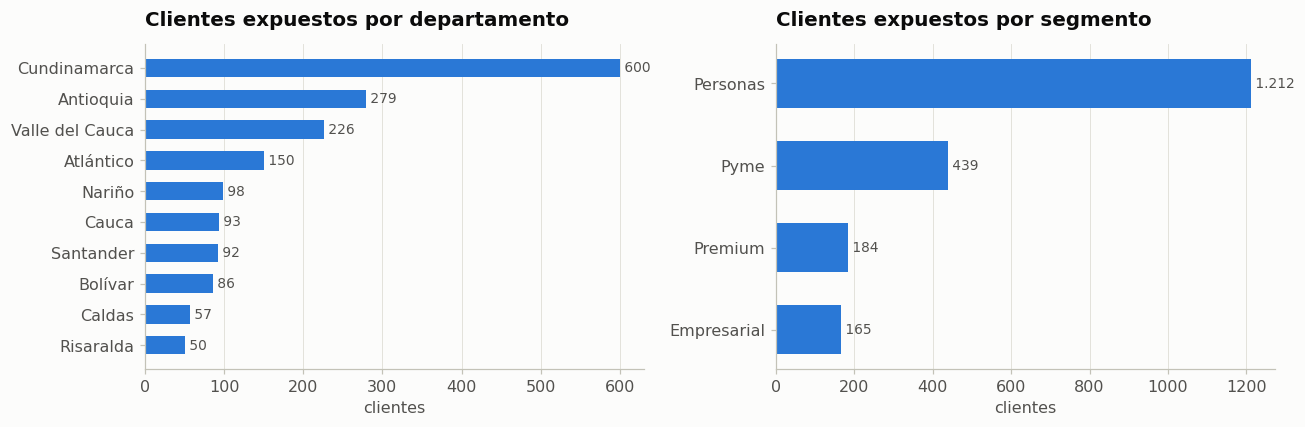

Listados para notificación (Ley 1581 de 2012): salida/registros_expuestos_clientes.csv y registros_expuestos_empleados.csv


In [29]:
if BD_DISPONIBLE:
    ids_cli = sorted(int(i) for i in expuestos.loc[expuestos['tabla'] == 'clientes', 'id'])
    ids_emp = sorted(int(i) for i in expuestos.loc[expuestos['tabla'] == 'empleados', 'id'])
    with cn.cursor() as cur:
        cur.execute(f"SELECT id, tipo_documento, nombres, apellidos, correo, telefono, ciudad, departamento, segmento "
                    f"FROM clientes WHERE id IN ({','.join(map(str, ids_cli)) or 'NULL'})")
        clientes_exp = pd.DataFrame(cur.fetchall())
        cur.execute(f"SELECT id, usuario, nombres, apellidos, correo, departamento, rol "
                    f"FROM empleados WHERE id IN ({','.join(map(str, ids_emp)) or 'NULL'})")
        empleados_exp = pd.DataFrame(cur.fetchall())
        cur.execute("SELECT table_name AS tabla, column_name AS columna FROM information_schema.columns "
                    "WHERE table_schema = DATABASE() AND table_name IN ('clientes', 'empleados') ORDER BY table_name, ordinal_position")
        columnas = pd.DataFrame(cur.fetchall())
    clientes_exp.to_csv(SALIDA / 'registros_expuestos_clientes.csv', index=False)
    empleados_exp.to_csv(SALIDA / 'registros_expuestos_empleados.csv', index=False)

    SENSIBLES = {'numero_documento': 'Documento de identidad', 'documento': 'Documento de identidad', 'correo': 'Contacto',
                 'telefono': 'Contacto', 'direccion': 'Contacto', 'fecha_nacimiento': 'Dato personal', 'saldo': 'Financiero',
                 'cupo_credito': 'Financiero', 'salario': 'Financiero (salario)', 'password_hash': 'Credencial (hash bcrypt)'}
    columnas['categoria'] = columnas['columna'].map(SENSIBLES).fillna('—')
    display(columnas[columnas['categoria'] != '—'].groupby('tabla')['categoria'].agg(lambda s: ', '.join(sorted(set(s)))).to_frame('datos sensibles expuestos'))

    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    for ax, (col, tit) in zip(axs, [('departamento', 'Clientes expuestos por departamento'), ('segmento', 'Clientes expuestos por segmento')]):
        conteo = clientes_exp[col].value_counts().head(10).sort_values()
        ax.barh(conteo.index, conteo.values, color=AZUL, height=0.6)
        for y, v in enumerate(conteo.values):
            ax.text(v, y, ' ' + num(v), va='center', fontsize=9, color=TINTA2)
        ax.set_title(tit); ax.grid(axis='y', visible=False); ax.set_xlabel('clientes')
    fig.tight_layout()
    guardar(fig, 'fig05_clientes_expuestos')
    print(f'Listados para notificación (Ley 1581 de 2012): {SALIDA.name}/registros_expuestos_clientes.csv y registros_expuestos_empleados.csv')

**¿Qué encontramos?** De los **clientes** salieron documentos de identidad, datos de contacto, fecha de nacimiento y datos financieros (saldo y cupo de crédito). De los **empleados**, además de sus datos de contacto, el **salario** y el **hash de la contraseña** del portal. Un hash no es la contraseña, pero con él un atacante puede intentar adivinarla sin límite de intentos: por eso todos los empleados deben cambiarla. Los listados quedaron en `salida/` para la notificación.

### 7.4 ¿En qué se diferencia del robo una exportación autorizada?

Finanzas y Gerencia también descargaron la tabla completa de clientes en la semana. En cantidad de datos se parece mucho al robo. La diferencia está en el **contexto**: quién lo hizo, desde dónde, con qué cuenta y si estaba aprobado.

In [30]:
display(con.sql('''
    SELECT d.ts, w.client_ip, w.usuario, d.db_user, d.ruta, d.tables[1] AS tabla, d.rows_sent
    FROM db_c d JOIN web w USING (request_id)
    WHERE d.rows_sent >= 400 AND d.tables[1] IN ('clientes', 'empleados') ORDER BY d.ts
''').df())

,ts,client_ip,usuario,db_user,ruta,tabla,rows_sent
0,2026-11-04 10:13:10.036,10.10.3.112,lmora,techcorp_app,/reportes/exportar.php,clientes,2000
1,2026-11-06 01:57:24.506,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
2,2026-11-06 01:57:39.507,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
3,2026-11-06 01:57:54.507,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
4,2026-11-06 01:58:09.509,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,clientes,500
5,2026-11-06 01:58:24.505,203.0.113.66,None,techcorp_admin,/uploads/avatars/thumb_8f3a.php,empleados,500
6,2026-11-09 16:42:18.174,10.10.6.139,lcaicedo,techcorp_app,/reportes/exportar.php,clientes,2000


**¿Qué encontramos?**

| | Exportaciones legítimas | El atacante |
|---|---|---|
| ¿Quién? | Un empleado con nombre y **sesión iniciada** | **Nadie**: sin sesión |
| ¿Desde dónde? | IP de la oficina | IP de Internet |
| ¿Por qué página? | `/reportes/exportar.php` (la función del portal) | La **webshell** |
| ¿Con qué cuenta de BD? | `techcorp_app` (mínimo privilegio) | `techcorp_admin` (todos los permisos) |
| ¿Estaba aprobado? | Sí (CAB-2026-117 y CAB-2026-121) | No |

El volumen de datos por sí solo no distingue un robo de un trabajo legítimo: lo distingue el **contexto**.

## 8. ¿Cuánto salió y hacia dónde? (exfiltración)

**¿Qué buscamos?** Confirmar que los datos **salieron** del servidor (no basta con que el atacante los haya leído), cuánto pesaban y quién se los llevó. Las descargas se hicieron por la webshell con el parámetro `dl` (de *download*), y el servidor web anotó el tamaño exacto de cada respuesta.

In [31]:
descargas = ws[ws['tipo'] == 'descarga'][['ts', 'client_ip', 'user_agent', 'orden', 'bytes_sent']].rename(columns={'orden': 'archivo'})
display(descargas.style.format({'bytes_sent': '{:,}'}).hide(axis='index'))
BYTES_EXFIL = int(descargas['bytes_sent'].sum())
mayor_legitima = con.sql(f'''SELECT MAX(bytes_sent) FROM web WHERE client_ip NOT IN ('203.0.113.66', '203.0.113.67')''').fetchone()[0]
print(f'Total exfiltrado: {mb(BYTES_EXFIL)} en {len(descargas)} descargas desde {", ".join(descargas["client_ip"].unique())}')
print(f'La descarga más grande es {descargas["bytes_sent"].max() / mayor_legitima:.0f}× la mayor respuesta legítima de la semana '
      f'({num(mayor_legitima / 1024)} KB) y {num(descargas["bytes_sent"].max() / p99)}× el percentil 99.')

ts,client_ip,user_agent,archivo,bytes_sent
2026-11-06 01:59:35.500000,203.0.113.67,curl/8.5.0,/tmp/.d.tgz,"163,525"
2026-11-06 02:00:16.500000,203.0.113.67,curl/8.5.0,/tmp/.w.tgz,"7,885,732"


Total exfiltrado: 7,68 MB en 2 descargas desde 203.0.113.67
La descarga más grande es 31× la mayor respuesta legítima de la semana (251 KB) y 3.400× el percentil 99.


**¿Qué encontramos?** Salieron **varios MB** en **dos descargas**: el paquete con las tablas robadas y la copia de todo el código del portal. La descarga más grande es **decenas de veces** mayor que la respuesta legítima más grande de toda la semana (las cifras exactas, arriba).

**Un detalle que engaña a un análisis apresurado:** las descargas **no** las hizo la IP que atacó (`203.0.113.66`), sino **otra** (`203.0.113.67`), con otra herramienta (`curl`), que aparece **solo dos veces en toda la semana**. Si hubiéramos buscado únicamente por la IP del ataque, el robo habría pasado desapercibido. Por eso seguimos el **artefacto** (la webshell) y no solo la IP: el atacante puede cambiar de IP, pero tiene que usar su puerta trasera.

## 9. La película completa: línea de tiempo unificada (*super-timeline*)

**¿Qué buscamos?** Hasta aquí miramos cada fuente por separado. Ahora ponemos **las cuatro en un mismo reloj** para ver el ataque como una película: cada fila del gráfico es un tipo de evento y cada punto, un momento. Esta es normalmente **la figura principal** de un informe forense.

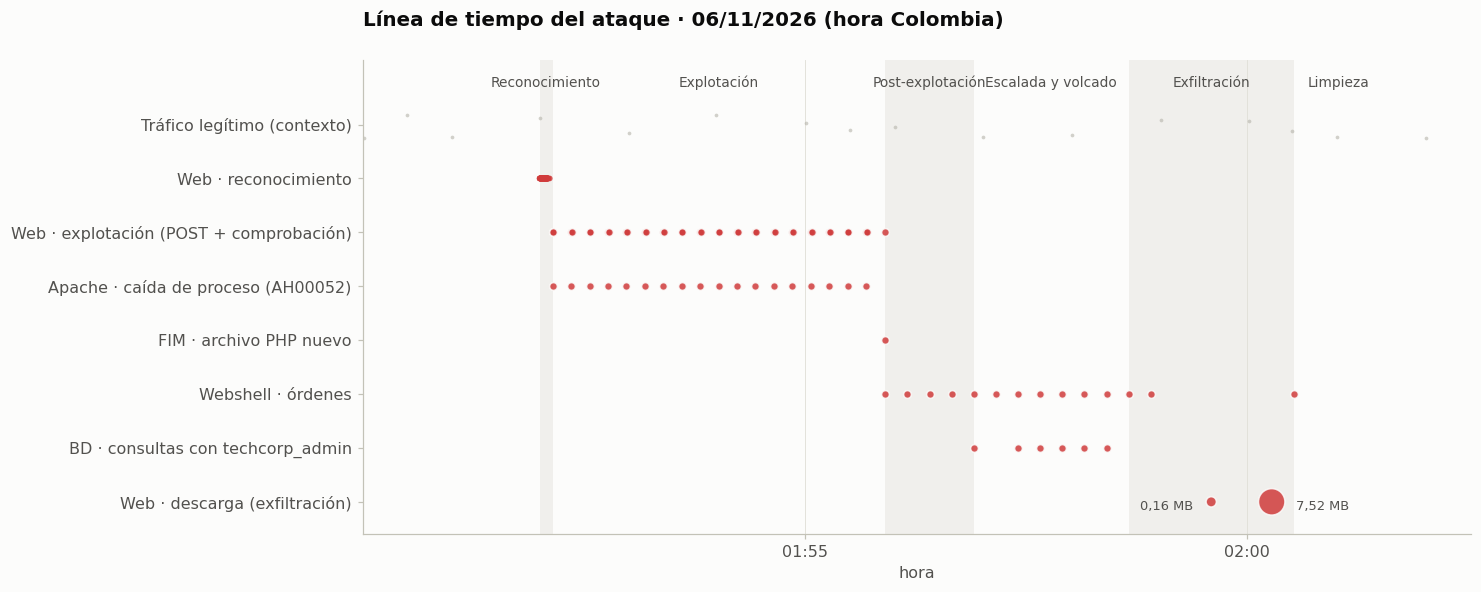

In [32]:
IPS_ATAQUE = sorted(set(ws['client_ip']) | set(posts['client_ip']))
T_INI = pd.Timestamp(con.sql('SELECT MIN(ts) FROM web WHERE client_ip IN (SELECT UNNEST(?::VARCHAR[]))', params=[IPS_ATAQUE]).fetchone()[0])
T_FIN = pd.Timestamp(con.sql('SELECT MAX(ts) FROM web WHERE client_ip IN (SELECT UNNEST(?::VARCHAR[]))', params=[IPS_ATAQUE]).fetchone()[0])

web_atk = con.sql('''
    SELECT ts, client_ip, method, uri, query, status, bytes_sent, bytes_received, user_agent, content_type, request_id
    FROM web WHERE client_ip IN (SELECT UNNEST(?::VARCHAR[])) ORDER BY ts
''', params=[IPS_ATAQUE]).df()

def carril(f):
    if f.uri == WEBSHELL and f.status == 200:
        return 'Web · descarga (exfiltración)' if 'dl=' in (f.query or '') else 'Webshell · órdenes'
    if f.method == 'POST' and (f.content_type or '').startswith('multipart'):
        return 'Web · explotación (POST + comprobación)'
    if f.uri == WEBSHELL:   # comprobaba con GET si la webshell ya existía (404)
        return 'Web · explotación (POST + comprobación)'
    return 'Web · reconocimiento'

web_atk['carril'] = web_atk.apply(carril, axis=1)
eventos = [web_atk[['ts', 'carril', 'bytes_sent']].assign(fuente='web')]
eventos.append(caidas[['ts_caida']].rename(columns={'ts_caida': 'ts'}).assign(carril='Apache · caída de proceso (AH00052)', bytes_sent=0, fuente='app'))
eventos.append(fim_php[['ts']].assign(carril='FIM · archivo PHP nuevo', bytes_sent=0, fuente='fim'))
eventos.append(consultas[consultas['db_user'] == 'techcorp_admin'][['ts']].assign(carril='BD · consultas con techcorp_admin', bytes_sent=0, fuente='db'))
tl = pd.concat(eventos, ignore_index=True).sort_values('ts')

contexto = con.sql('''
    SELECT ts FROM web WHERE ts BETWEEN ? AND ? AND client_ip NOT IN (SELECT UNNEST(?::VARCHAR[]))
''', params=[(T_INI - pd.Timedelta(minutes=5)).to_pydatetime(), (T_FIN + pd.Timedelta(minutes=5)).to_pydatetime(), IPS_ATAQUE]).df()

FASES = {
    'Reconocimiento': T_INI,
    'Explotación': posts['ts'].min(),
    'Post-explotación': primer_200,
    'Escalada y volcado': consultas.loc[consultas['db_user'] == 'techcorp_admin', 'ts'].min(),
    'Exfiltración': ws.loc[ws['orden'].str.startswith('tar'), 'ts'].min(),
    'Limpieza': ws.loc[ws['orden'].str.startswith('rm '), 'ts'].min(),
}
CARRILES = ['Tráfico legítimo (contexto)', 'Web · reconocimiento', 'Web · explotación (POST + comprobación)', 'Apache · caída de proceso (AH00052)',
            'FIM · archivo PHP nuevo', 'Webshell · órdenes', 'BD · consultas con techcorp_admin', 'Web · descarga (exfiltración)']
y = {c: i for i, c in enumerate(reversed(CARRILES))}

fig, ax = plt.subplots(figsize=(13, 5.6))
limites = list(FASES.values()) + [T_FIN + pd.Timedelta(minutes=1)]
for i, (nombre, ini) in enumerate(FASES.items()):
    if i % 2 == 0:
        ax.axvspan(ini, limites[i + 1], color='#f0efec', zorder=0, lw=0)
    ax.text(ini + (limites[i + 1] - ini) / 2, len(CARRILES) - 0.35, nombre, ha='center', va='bottom', fontsize=9, color=TINTA2)
ax.scatter(contexto['ts'], np.full(len(contexto), y['Tráfico legítimo (contexto)']) + np.random.default_rng(0).uniform(-0.25, 0.25, len(contexto)),
           s=6, color=GRIS, alpha=0.6, lw=0, zorder=2)
for c in CARRILES[1:]:
    d = tl[tl['carril'] == c]
    tam = 26 if not c.endswith('(exfiltración)') else 40 + 260 * d['bytes_sent'] / max(1, d['bytes_sent'].max())
    denso = len(d) > 60   # ráfagas (gobuster): sin borde para que se lea como una franja continua
    ax.scatter(d['ts'], np.full(len(d), y[c]), s=tam if not denso else 14, color=CRITICO, alpha=0.85,
               edgecolor='none' if denso else FONDO, linewidth=1, zorder=3)
d = tl[tl['carril'] == 'Web · descarga (exfiltración)']
for i, (_, f) in enumerate(d.iterrows()):
    ax.annotate(mb(f['bytes_sent']), (f['ts'], y['Web · descarga (exfiltración)']), xytext=(-12 if i % 2 == 0 else 16, -3),
                textcoords='offset points', ha='right' if i % 2 == 0 else 'left', va='center', fontsize=8.5, color=TINTA2)
ax.set_yticks(list(y.values()), list(y.keys()))
ax.set_ylim(-0.6, len(CARRILES) + 0.2)
ax.grid(axis='y', visible=False)
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.set_xlim(T_INI - pd.Timedelta(minutes=2), T_FIN + pd.Timedelta(minutes=2))
ax.set_title(f"Línea de tiempo del ataque · {T_INI:%d/%m/%Y} (hora Colombia)", pad=22)
ax.set_xlabel('hora')
guardar(fig, 'fig06_linea_tiempo_ataque')

**¿Cómo se lee?** De izquierda a derecha corre el reloj; cada fila es un tipo de evento. El ataque completo, fase por fase:

* **Reconocimiento**: la ráfaga de gobuster (puntos rojos juntos) mientras el tráfico normal (gris) sigue su curso.
* **Explotación**: cada subida a la página de la foto tiene, justo debajo, su **caída de Apache**. Al final, un solo punto en el FIM: **nace la webshell**.
* **Post-explotación**: empiezan las órdenes por la webshell.
* **Escalada y volcado**: las órdenes coinciden en el tiempo con las consultas de `techcorp_admin` en la base de datos.
* **Exfiltración**: las dos descargas (el tamaño del punto es el peso de cada una).
* **Limpieza**: la orden de borrado.

Cada fase está confirmada por **al menos dos fuentes independientes**.

In [33]:
def hito(ts, fuente, descripcion):
    return {'hora': ts, 'fuente': fuente, 'evento': descripcion}

recon = web_atk[web_atk['carril'] == 'Web · reconocimiento']
gob = recon[recon['user_agent'].str.startswith('gobuster')]
hitos = [
    hito(T_INI, 'web', f"Primer acceso de {web_atk.iloc[0]['client_ip']} con navegador ({web_atk.iloc[0]['user_agent'][:40]}…)"),
    hito(gob['ts'].min(), 'web', f"Enumeración de rutas con gobuster: {len(gob)} peticiones ({(gob['status'] == 404).sum()} 404) en {(gob['ts'].max() - gob['ts'].min()).total_seconds():.0f} s"),
    hito(posts['ts'].min(), 'web', f"Inicia la ráfaga de subidas enormes a /empleados/foto.php ({len(posts)} en total, {(posts['status'] == 500).sum()} con error 500)"),
    hito(caidas['ts_caida'].min(), 'app', f"Primera caída de proceso de Apache (Segmentation fault); {len(caidas)} en total"),
    hito(ultimo_post.ts, 'web', 'POST explotador exitoso (respuesta sin error)'),
    hito(T_IMPLANTE, 'fim', f'Se crea {fim_php.iloc[0]["path"]}'),
    hito(primer_200, 'web', 'Primer uso de la webshell'),
]
for _, f in ws[ws['tipo'] != 'acceso'].iterrows():
    hito_txt = ('Descarga ' + f['orden'] + f' ({mb(f["bytes_sent"])}) desde ' + f['client_ip']) if f['tipo'] == 'descarga' else 'Orden: ' + f['orden_segura']
    hitos.append(hito(f['ts'], 'web', hito_txt))
for _, f in consultas[consultas['db_user'] == 'techcorp_admin'].iterrows():
    hitos.append(hito(f['ts'], 'db', f"[{f['db_user']}] {f['sql']} → {f['rows_sent']} filas"))
super_timeline = pd.DataFrame(hitos).sort_values('hora').reset_index(drop=True)
super_timeline.to_csv(SALIDA / 'super_timeline.csv', index=False)
pd.set_option('display.max_colwidth', 140)
display(super_timeline.style.hide(axis='index'))

hora,fuente,evento
2026-11-06 01:52:00.100000,web,Primer acceso de 203.0.113.66 con navegador (gobuster/3.6…)
2026-11-06 01:52:00.100000,web,Enumeración de rutas con gobuster: 61 peticiones (48 404) en 7 s
2026-11-06 01:52:09,web,"Inicia la ráfaga de subidas enormes a /empleados/foto.php (19 en total, 18 con error 500)"
2026-11-06 01:52:09,app,Primera caída de proceso de Apache (Segmentation fault); 18 en total
2026-11-06 01:55:54,web,POST explotador exitoso (respuesta sin error)
2026-11-06 01:55:54,fim,Se crea /var/www/html/uploads/avatars/thumb_8f3a.php
2026-11-06 01:55:54.500000,web,Primer uso de la webshell
2026-11-06 01:56:09.500000,web,Orden: id
2026-11-06 01:56:24.500000,web,Orden: php -v
2026-11-06 01:56:39.500000,web,Orden: cat /var/www/html/config/database.php


**¿Qué encontramos?** La misma historia en forma de tabla, evento por evento, con la fuente que lo respalda. Se guarda en `salida/super_timeline.csv` para anexarla al informe.

## 10. Conclusiones: las respuestas a las cinco preguntas

Ya podemos responder lo que nos pidieron. Cada respuesta se calcula a partir de la evidencia (no está escrita a mano): si los registros fueran otros, las respuestas cambiarían solas.

In [34]:
n_cli = int(resumen_exp.loc[resumen_exp['tabla'] == 'clientes', 'registros'].sum())
n_emp = int(resumen_exp.loc[resumen_exp['tabla'] == 'empleados', 'registros'].sum())
permanencia = T_FIN - T_INI
ip_origen = posts['client_ip'].mode()[0]
ips_exfil = ', '.join(sorted(descargas['client_ip'].unique()))

display(Markdown(f'''
| Pregunta | Respuesta (evidencia) |
|---|---|
| **¿Cuándo?** | Del **{T_INI:%d/%m/%Y %H:%M:%S}** al **{T_FIN:%H:%M:%S}** (hora Colombia): **{permanencia.total_seconds() / 60:.0f} minutos** de actividad. Explotación exitosa: **{T_IMPLANTE:%H:%M:%S}**. Exfiltración: **{descargas["ts"].min():%H:%M:%S}–{descargas["ts"].max():%H:%M:%S}**. |
| **¿Dónde?** | Servidor **web-01** (portal interno, PHP 8.3.30 + Apache). Punto de entrada: la página de subir la foto de perfil, **`/empleados/foto.php`** (el ataque dispara la falla **sin necesidad de iniciar sesión**). Artefacto: **`{fim_php.iloc[0]["path"]}`**. Base de datos **db-01**, esquema `techcorp`. |
| **¿Cómo?** | **{len(posts)} subidas de archivo** a la página de la foto, con el campo `PHP_SESSION_UPLOAD_PROGRESS` y de hasta {num(posts["bytes_received"].max() / 1024)} KB (una foto normal pesa ~50 KB): el patrón de **PHP2Shell (CVE-2026-109618)**. Hubo {len(caidas)} caídas de proceso antes de lograr la **webshell**. Desde ella leyó `config/database.php`, obtuvo la cuenta **`techcorp_admin`** (escalada), volcó las tablas a `/tmp/.d`, las comprimió y las descargó. |
| **¿Quién / desde dónde?** | IP de origen **{ip_origen}** (reconocimiento con `gobuster/3.6`, explotación con `python-requests`). Exfiltración desde **{ips_exfil}** (`curl/8.5.0`). Ambas son externas y no figuran en el inventario ni en el registro de cambios. |
| **¿Qué registros?** | **{num(n_cli)} clientes** (todos: documento, contacto, saldo y cupo) y **{num(n_emp)} empleados** (incluidos **salario** y **hash de contraseña**). Se extrajeron **{mb(BYTES_EXFIL)}**: los volcados y una copia del código fuente del portal con las fotos de perfil. |
'''))


| Pregunta | Respuesta (evidencia) |
|---|---|
| **¿Cuándo?** | Del **06/11/2026 01:52:00** al **02:00:31** (hora Colombia): **9 minutos** de actividad. Explotación exitosa: **01:55:54**. Exfiltración: **01:59:35–02:00:16**. |
| **¿Dónde?** | Servidor **web-01** (portal interno, PHP 8.3.30 + Apache). Punto de entrada: la página de subir la foto de perfil, **`/empleados/foto.php`** (el ataque dispara la falla **sin necesidad de iniciar sesión**). Artefacto: **`/var/www/html/uploads/avatars/thumb_8f3a.php`**. Base de datos **db-01**, esquema `techcorp`. |
| **¿Cómo?** | **19 subidas de archivo** a la página de la foto, con el campo `PHP_SESSION_UPLOAD_PROGRESS` y de hasta 670 KB (una foto normal pesa ~50 KB): el patrón de **PHP2Shell (CVE-2026-109618)**. Hubo 18 caídas de proceso antes de lograr la **webshell**. Desde ella leyó `config/database.php`, obtuvo la cuenta **`techcorp_admin`** (escalada), volcó las tablas a `/tmp/.d`, las comprimió y las descargó. |
| **¿Quién / desde dónde?** | IP de origen **203.0.113.66** (reconocimiento con `gobuster/3.6`, explotación con `python-requests`). Exfiltración desde **203.0.113.67** (`curl/8.5.0`). Ambas son externas y no figuran en el inventario ni en el registro de cambios. |
| **¿Qué registros?** | **2.000 clientes** (todos: documento, contacto, saldo y cupo) y **500 empleados** (incluidos **salario** y **hash de contraseña**). Se extrajeron **7,68 MB**: los volcados y una copia del código fuente del portal con las fotos de perfil. |


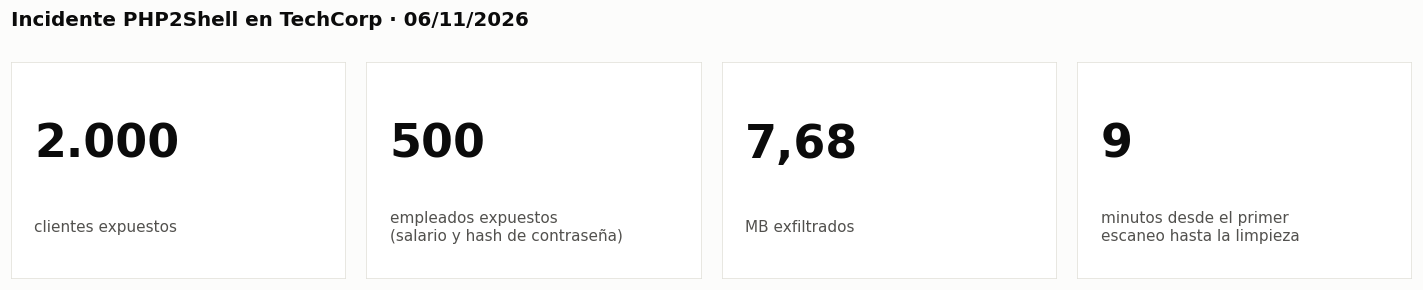

In [35]:
# Figura resumen para la diapositiva de cierre (cifras clave)
cifras = [(num(n_cli), 'clientes expuestos'), (num(n_emp), 'empleados expuestos\n(salario y hash de contraseña)'),
          (mb(BYTES_EXFIL).replace(' MB', ''), 'MB exfiltrados'), (f'{permanencia.total_seconds() / 60:.0f}', 'minutos desde el primer\nescaneo hasta la limpieza')]
fig, axs = plt.subplots(1, 4, figsize=(13, 2.6))
fig.subplots_adjust(left=0.01, right=0.99, top=0.80, bottom=0.04, wspace=0.06)
for ax, (valor, etiqueta) in zip(axs, cifras):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, facecolor='#ffffff', edgecolor=REJILLA, lw=1))
    ax.text(0.07, 0.62, valor, fontsize=30, fontweight='semibold', color=TINTA, transform=ax.transAxes, va='center')
    ax.text(0.07, 0.24, etiqueta, fontsize=10, color=TINTA2, transform=ax.transAxes, va='center')
fig.suptitle(f'Incidente PHP2Shell en TechCorp · {T_INI:%d/%m/%Y}', x=0.01, ha='left', fontsize=13, fontweight='semibold')
guardar(fig, 'fig07_cifras_clave')

In [36]:
# Indicadores de compromiso (IOC) para bloquear y buscar en otros sistemas
iocs = {
    'ips': [{'ip': ip, 'rol': 'reconocimiento y explotación' if ip == ip_origen else 'exfiltración'} for ip in IPS_ATAQUE],
    'user_agents': sorted(web_atk['user_agent'].unique()),
    'archivos': [{'ruta': fim_php.iloc[0]['path'], 'sha256': fim_php.iloc[0]['sha256'], 'tipo': 'webshell'},
                 {'ruta': '/tmp/.d/, /tmp/.d.tgz, /tmp/.w.tgz', 'tipo': 'preparación y empaquetado (borrados por el atacante)'}],
    'uris': [WEBSHELL, '/empleados/foto.php (subida multipart con PHP_SESSION_UPLOAD_PROGRESS)'],
    'cuentas_comprometidas': ['techcorp_admin (BD)', 'techcorp_app (BD, contraseña expuesta en config)', f'{n_emp} cuentas del portal (hash bcrypt filtrado)'],
    'vulnerabilidad': 'PHP 8.3.30 < 8.3.36: PHP2Shell (CVE-2026-109618 / CVE-2026-109619)',
}
(SALIDA / 'iocs.json').write_text(json.dumps(iocs, ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(iocs, ensure_ascii=False, indent=2))

{
  "ips": [
    {
      "ip": "203.0.113.66",
      "rol": "reconocimiento y explotación"
    },
    {
      "ip": "203.0.113.67",
      "rol": "exfiltración"
    }
  ],
  "user_agents": [
    "curl/8.5.0",
    "gobuster/3.6",
    "python-requests/2.32.3"
  ],
  "archivos": [
    {
      "ruta": "/var/www/html/uploads/avatars/thumb_8f3a.php",
      "sha256": "a0a401e8e0260ef38cb542a3c867cb717d66b364bdecb99cc81182522e153c1e",
      "tipo": "webshell"
    },
    {
      "ruta": "/tmp/.d/, /tmp/.d.tgz, /tmp/.w.tgz",
      "tipo": "preparación y empaquetado (borrados por el atacante)"
    }
  ],
  "uris": [
    "/uploads/avatars/thumb_8f3a.php",
    "/empleados/foto.php (subida multipart con PHP_SESSION_UPLOAD_PROGRESS)"
  ],
  "cuentas_comprometidas": [
    "techcorp_admin (BD)",
    "techcorp_app (BD, contraseña expuesta en config)",
    "500 cuentas del portal (hash bcrypt filtrado)"
  ],
  "vulnerabilidad": "PHP 8.3.30 < 8.3.36: PHP2Shell (CVE-2026-109618 / CVE-2026-109619)"
}


### Recomendaciones (cada una nace de un hallazgo)

**Contención inmediata**
1. Aislar el servidor `web-01`, hacer una copia de su disco y de su memoria, y solo después borrar la webshell. *(La webshell todavía está ahí: es la puerta trasera del atacante.)*
2. Bloquear 203.0.113.66 y 203.0.113.67, y vigilar todo el bloque 203.0.113.0/24. *(El atacante usó dos IP del mismo bloque.)*
3. Cambiar **todas** las contraseñas: `techcorp_admin`, `techcorp_app` y las de los 500 empleados. *(Las dos primeras estaban en el archivo leído y los hashes de las demás salieron.)*

**Erradicación y recuperación**

4. Actualizar PHP a **8.3.36 o superior** y reconstruir el servidor desde una imagen limpia. *(La causa raíz: PHP sin parche.)*
5. Prohibir que se ejecuten programas en la carpeta `/uploads`, ocultar la versión de PHP (`expose_php = Off`) y desactivar `session.upload_progress.enabled` si no se usa. *(La webshell funcionó porque esa carpeta ejecuta PHP; la versión vulnerable se anunciaba en cada respuesta.)*
6. Sacar las contraseñas de las carpetas del sitio web (usar un gestor de secretos) y eliminar la cuenta de mantenimiento con todos los permisos. *(Sin esa contraseña a la vista, no habría habido escalada.)*

**Detección y cumplimiento**

7. Enviar los cuatro registros, **en el momento**, a un SIEM fuera del servidor, con alertas para: ráfagas de errores 500, subidas grandes sin sesión, archivos `.php` nuevos en `/uploads` y uso de cuentas de base de datos fuera de lo habitual. *(Cada una de esas alertas habría saltado esa madrugada.)*
8. Controlar el tráfico de salida y las respuestas anormalmente grandes. *(Salieron varios MB hacia una IP desconocida en plena madrugada.)*
9. **Ley 1581 de 2012:** reportar el incidente a la **SIC** y notificar a los 2000 clientes y 500 empleados, con los listados generados en `salida/`.

### Las expresiones regulares del caso

Repasemos el papel de las expresiones regulares en la investigación. Cada pregunta importante se respondió, en algún punto, con un patrón:

| Sección | Patrón | Qué resolvió |
|---|---|---|
| 0.1 | `\b(?:\d{1,3}\.){3}\d{1,3}\b` | Reconocer direcciones IP dentro de texto libre |
| 3 | `\d+` → `N` | Agrupar páginas que solo cambian en un número (la línea base) |
| 4.6 | `^/uploads/.*\.php$` y `[?&](x\|dl)=[A-Za-z0-9+/]{4,}={0,2}$` | Firmas que **solo** coinciden con el atacante, entre ~80 000 peticiones |
| 4.6 | firmas de inyección SQL y de `../` | Descartar ataques: 0 coincidencias también es un hallazgo |
| 6 | `-p'[^']*'` | Tapar contraseñas antes de mostrarlas (proteger la evidencia sensible) |
| 6 | `^(id\|whoami\|…)`, `^cat .*config`, `^rm ` … | Clasificar cada orden del atacante en MITRE ATT&CK |
| 6.1 | `"SELECT \* FROM (\w+)…" > (\S+)$` y `tar czf (\S+) …` | Reconstruir los archivos que el atacante **borró** |
| 7 | `request_id='([^']+)'` | **La llave del caso**: unir la base de datos con el servidor web |
| 7.1 | `\s*/\*.*\*/` | Quitar el comentario y quedarse con el SQL limpio |

**Tres lecciones:**

1. **Una regex convierte texto en datos.** Los logs son texto; los grupos de captura `( )` sacan de ese texto los campos que luego se cuentan, se cruzan y se grafican.
2. **Lo específico gana a lo general.** Las firmas generales (escáneres, herramientas) atrapan ruido de Internet; las específicas de este ataque atrapan solo al atacante. Una buena regex forense describe **exactamente** la huella que se busca.
3. **Una regex solo ve lo que quedó escrito.** El exploit iba en el **cuerpo** de las subidas, que el servidor no guarda: ningún patrón sobre la URL podía verlo. Ahí hizo falta otro método (tamaños, errores 500 y caídas, sección 5).

## 11. Cierre: la evidencia sigue intacta

Volvemos a calcular la huella SHA-256 de cada archivo de registro y la comparamos con la que anotamos en el paso 1. Si todas coinciden, queda demostrado que **el análisis no modificó la evidencia**, y la cadena de custodia se cierra.

In [37]:
verif = custodia[['archivo', 'sha256']].copy()
verif['sha256_final'] = [sha256(EVIDENCIA / a) for a in verif['archivo']]
verif['intacto'] = verif['sha256'] == verif['sha256_final']
display(verif[['archivo', 'intacto']])
print('OK: la evidencia no cambió durante el análisis.' if verif['intacto'].all() else 'ATENCIÓN: algún archivo cambió.')

,archivo,intacto
0,app/app.jsonl,True
1,db/audit.jsonl,True
2,fim/fim.jsonl,True
3,web/access.jsonl,True


OK: la evidencia no cambió durante el análisis.


**¿Qué encontramos?** Las cuatro huellas son idénticas antes y después: la evidencia está **intacta** y las conclusiones se pueden presentar.

### Comprobación del laboratorio (solo para el docente)

Como el incidente es simulado, existe un «solucionario» con lo que el generador inyectó de verdad. Esta celda compara nuestras conclusiones con él. En un caso real, por supuesto, no existe.

In [38]:
# Solo para el docente: compara las conclusiones con lo que el generador realmente inyectó
ruta_sol = SOLUCIONARIO / 'solucionario_incidente.json' if SOLUCIONARIO else None
if ruta_sol and ruta_sol.exists():
    sol = json.loads(ruta_sol.read_text(encoding='utf-8'))
    ini_real = pd.Timestamp(sol['fases']['1_reconocimiento']['inicio_local']).tz_localize(None)
    fin_real = pd.Timestamp(sol['fin_local']).tz_localize(None)
    checks = pd.DataFrame([
        ('IP de origen', ip_origen, sol['ip_origen']),
        ('IP de exfiltración', ips_exfil, sol['ip_exfiltracion']),
        ('Webshell', WEBSHELL, sol['webshell']),
        ('Cuenta de BD usada', 'techcorp_admin' if (consultas['db_user'] == 'techcorp_admin').any() else '-', sol['cuenta_bd_usada']),
        ('Intentos de explotación', len(posts), sol['intentos_explotacion']),
        ('Bytes exfiltrados (±1 %: el log de Apache incluye cabeceras)', BYTES_EXFIL, sol['bytes_exfiltrados']),
        ('Inicio (±1 s)', f'{T_INI:%H:%M:%S}', f'{ini_real:%H:%M:%S}'),
        ('Fin (±1 s)', f'{T_FIN:%H:%M:%S}', f'{fin_real:%H:%M:%S}'),
    ], columns=['dato', 'análisis', 'solucionario'])
    checks['¿coincide?'] = [str(a) == str(b) or (isinstance(a, int) and abs(a - b) <= max(1, 0.01 * b)) for a, b in zip(checks['análisis'], checks['solucionario'])]
    checks.loc[checks['dato'].str.startswith(('Inicio', 'Fin')), '¿coincide?'] = [abs((T_INI - ini_real).total_seconds()) <= 1, abs((T_FIN - fin_real).total_seconds()) <= 1]
    display(checks.style.hide(axis='index'))
else:
    print('No hay solucionario montado (es opcional).')

dato,análisis,solucionario,¿coincide?
IP de origen,203.0.113.66,203.0.113.66,True
IP de exfiltración,203.0.113.67,203.0.113.67,True
Webshell,/uploads/avatars/thumb_8f3a.php,/uploads/avatars/thumb_8f3a.php,True
Cuenta de BD usada,techcorp_admin,techcorp_admin,True
Intentos de explotación,19,19,True
Bytes exfiltrados (±1 %: el log de Apache incluye cabeceras),8049257,5770870,False
Inicio (±1 s),01:52:00,01:52:00,True
Fin (±1 s),02:00:31,02:27:08,False


---
## Mensaje final

El atacante hizo casi todo «bien» desde su punto de vista: usó una falla sin necesidad de contraseña, entró de madrugada, escaló privilegios con una contraseña olvidada, sacó los datos desde una IP distinta y **borró todo lo que usó**. Aun así, respondimos con precisión **cuándo** (la madrugada del 6 de noviembre, minuto a minuto), **dónde** (la página de la foto de perfil y la webshell), **cómo** (PHP2Shell, credenciales en texto plano y una cuenta con demasiados permisos), **quién** (203.0.113.66 y 203.0.113.67, con gobuster, python-requests y curl) y **qué** (los 2000 clientes y los 500 empleados, registro por registro).

Fue posible por tres razones:

1. **Varias fuentes independientes.** Ninguna sola cuenta la historia completa, pero juntas no dejan huecos, y cada hallazgo está confirmado por al menos dos.
2. **Identificadores que las unen.** La hora, el número de seguimiento de cada visita y la huella de cada archivo permiten cruzar lo que pasó en la web con lo que pasó en la base de datos.
3. **Registros fuera del alcance del atacante.** Borró sus archivos, pero no los registros de lo que hizo con ellos.

La última razón es también la mayor lección para TechCorp: en este laboratorio los registros quedaron a salvo, pero estaban **en el mismo servidor**. Un atacante más cuidadoso podría haberlos borrado también. Por eso la recomendación número 7 (enviarlos en el momento a un sistema aparte) es la que hace posible todo lo demás.